# Rendimiento de los cultivos en la región de Tacna (2021–2023): análisis exploratorio y modelos de regresión

**Curso:** Minería de Datos (Electivo III) · UNJBG · 2026-II  
**Evaluación:** Primera evaluación (Unidades 01 y 02) — proyecto académico: tabla analítica + modelos de regresión  
**Equipo / estudiante:** _(completar)_

---
### Problema y pregunta guía
La Dirección Regional de Agricultura de Tacna publica cada año el anuario agrícola con la producción, la superficie y el rendimiento de los cultivos por distrito.  
**Pregunta:** ¿de qué dependen las diferencias de **rendimiento (kg/ha)** entre cultivos y distritos de Tacna, y qué distritos rinden menos de lo esperado para el mismo cultivo?  
**Variable objetivo:** `rendimiento_kg_ha` (continua). **Unidad de observación:** un cultivo en un distrito en un año.

### Ruta del notebook (KDD / CRISP-DM)
1. Obtención y verificación de los datos  
2. Análisis exploratorio (visualizaciones base del laboratorio)  
3. Correlaciones y atributos derivados  
4. **Unidad 01:** preprocesamiento (faltantes, categóricas, atípicos, escalamiento, división) → tabla analítica  
5. **Unidad 02:** modelos de regresión frente a una línea base (MAE, RMSE, R²)  
6. De los datos a una propuesta: brechas de rendimiento y política  
7. Limitaciones, conclusiones y declaración de uso de IA

> **Fuente de datos:** Gobierno Regional de Tacna – Dirección Regional de Agricultura (DRAT), *Anuario Estadístico Agrícola 2021, 2022 y 2023: producción anual de alimentos por provincia, región o departamento de Tacna*, Plataforma Nacional de Datos Abiertos (datosabiertos.gob.pe). Los tres archivos Excel (tablas extraídas de PDF) se limpiaron y unieron con el script `parse_anuario.py`.

## 0. Pre-requisitos

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import sklearn

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.model_selection import (train_test_split, KFold, GroupKFold, cross_val_score,
                                     cross_validate, cross_val_predict, GridSearchCV, learning_curve)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import KNNImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rc("font", size=12); plt.rc("axes", labelsize=12, titlesize=13)
plt.rc("xtick", labelsize=10); plt.rc("ytick", labelsize=10)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python 3.12.3 | pandas 3.0.2 | scikit-learn 1.8.0


## 1. Obtención de los datos
El archivo `tabla_agricola_tacna_2021_2023.csv` contiene una fila por **cultivo × distrito × año**.  
Si ejecutas en Google Colab, la celda siguiente te pedirá subir el archivo.

In [2]:
CSV = "tabla_agricola_tacna_2021_2023.csv"
if not Path(CSV).exists():
    try:
        from google.colab import files
        print("Sube el archivo", CSV)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Coloca {CSV} junto al notebook")

raw = pd.read_csv(CSV)
print("Filas y columnas del archivo completo:", raw.shape)
print("\nFilas con distrito inferido (nombre ausente en el anuario original):")
print(raw.groupby(["anio", "distrito"]).size()[raw.groupby(["anio", "distrito"]).distrito_inferido.first()])

Filas y columnas del archivo completo: (1067, 14)

Filas con distrito inferido (nombre ausente en el anuario original):
anio  distrito 
2021  CALANA       31
      INCLAN       17
2022  ITE           6
      TARUCACHI     8
dtype: int64


**Decisión de calidad 1 — distritos inferidos.** En el anuario original, cuatro bloques de datos no traían el nombre del distrito y se asignaron por el orden de las hojas (Calana e Inclán en 2021; Ite y Tarucachi en 2022). Como no se pueden verificar con certeza, **se excluyen del análisis** para no contaminar las conclusiones por distrito.

In [3]:
agri = raw[~raw["distrito_inferido"]].copy().reset_index(drop=True)
print(f"Filas excluidas: {len(raw) - len(agri)}  |  filas que se conservan: {len(agri)}")
print(agri.groupby("anio").agg(filas=("cultivo", "size"), distritos=("distrito", "nunique"), cultivos=("cultivo", "nunique")))

Filas excluidas: 62  |  filas que se conservan: 1005
      filas  distritos  cultivos
anio                            
2021    309         24        54
2022    341         24        54
2023    355         26        53


## 2. Verificando los datos

In [4]:
agri.head()

,anio,provincia,distrito,tipo_cultivo,cultivo,produccion_t,sup_total_ha,sup_cosechada_ha,sup_crecimiento_ha,rendimiento_kg_ha,precio_chacra_s_kg,en_crecimiento_sin_cosecha,distrito_inferido,hoja_origen
0,2021,CANDARAVE,CAIRANI,PERMANENTE,ALFALFA,18642.0,1187.0,1187.0,0.0,15705.0,0.46,False,False,Table 13
1,2021,CANDARAVE,CAIRANI,SEMIPERMANENTE,OREGANO,430.0,103.0,103.0,0.0,4175.0,10.45,False,False,Table 13
2,2021,CANDARAVE,CAIRANI,TRANSITORIO,HABA GRANO VERDE,21.0,3.0,3.0,0.0,7000.0,1.67,False,False,Table 13
3,2021,CANDARAVE,CAIRANI,TRANSITORIO,MAIZ AMILACEO,75.0,25.0,25.0,0.0,3000.0,5.60,False,False,Table 13
4,2021,CANDARAVE,CAIRANI,TRANSITORIO,PAPA,683.0,31.0,31.0,0.0,22032.0,1.56,False,False,Table 13


In [5]:
agri.info()

<class 'pandas.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   anio                        1005 non-null   int64  
 1   provincia                   1005 non-null   str    
 2   distrito                    1005 non-null   str    
 3   tipo_cultivo                1005 non-null   str    
 4   cultivo                     1005 non-null   str    
 5   produccion_t                978 non-null    float64
 6   sup_total_ha                1005 non-null   float64
 7   sup_cosechada_ha            978 non-null    float64
 8   sup_crecimiento_ha          978 non-null    float64
 9   rendimiento_kg_ha           978 non-null    float64
 10  precio_chacra_s_kg          977 non-null    float64
 11  en_crecimiento_sin_cosecha  1005 non-null   bool   
 12  distrito_inferido           1005 non-null   bool   
 13  hoja_origen                 1005 non-null   

### Actividad 1 — Comprender el problema y la unidad de observación
1. ¿Qué representa cada fila? ¿Qué columnas describen ubicación, tiempo, cultivo y resultado productivo?
2. Distingue dos variables cuantitativas y dos categóricas. ¿Alguna categórica es ordinal o todas son nominales?
3. ¿Por qué `rendimiento_kg_ha` es una buena variable objetivo y por qué **no** debe usarse `produccion_t` como predictora? _(Pista: rendimiento = producción ÷ superficie cosechada.)_

**Respuestas:** _(completar)_

In [6]:
print("Valores faltantes por columna:")
faltantes = agri.isna().sum().to_frame("n_faltantes")
faltantes["%"] = (100 * faltantes["n_faltantes"] / len(agri)).round(1)
faltantes[faltantes["n_faltantes"] > 0]

Valores faltantes por columna:


,n_faltantes,%
produccion_t,27,2.7
sup_cosechada_ha,27,2.7
sup_crecimiento_ha,27,2.7
rendimiento_kg_ha,27,2.7
precio_chacra_s_kg,28,2.8


In [7]:
# ¿Qué cultivos no tienen rendimiento? (cultivos en crecimiento, aún sin cosecha)
sin_rend = agri["rendimiento_kg_ha"].isna()
print("Filas sin rendimiento:", sin_rend.sum())
print(agri.loc[sin_rend, "cultivo"].value_counts().to_dict())
print("\nFilas con rendimiento pero sin precio en chacra:")
agri.loc[~sin_rend & agri["precio_chacra_s_kg"].isna(), ["anio", "distrito", "cultivo", "rendimiento_kg_ha"]]

Filas sin rendimiento: 27
{'PALTO': 8, 'TUNA (COCHINILLA)': 7, 'GRANADO': 6, 'MELOCOTON': 3, 'TUNA': 2, 'NARANJA': 1}

Filas con rendimiento pero sin precio en chacra:


,anio,distrito,cultivo,rendimiento_kg_ha
411,2022,CORONEL GREGORIO ALBARRACIN LANCHIPA,NARANJO,31562.5


### Actividad 2 — Valores faltantes
1. ¿Cuántos valores faltan en cada columna y **por qué** faltan? Distingue un faltante *estructural* (el dato no existe: el cultivo aún no se cosecha) de uno *accidental* (el dato existe pero no se registró).
2. ¿Cuál es la diferencia entre un valor nulo y un cero? ¿Qué pasaría si trataras los 27 faltantes de rendimiento como ceros?

**Respuestas:** _(completar)_

In [8]:
for col in ["provincia", "tipo_cultivo", "anio"]:
    print(agri[col].value_counts().to_string(), "\n")
print("Cultivos más frecuentes:")
agri["cultivo"].value_counts().head(15)

provincia
TACNA            554
TARATA           237
JORGE BASADRE    109
CANDARAVE        105 

tipo_cultivo
TRANSITORIO       557
PERMANENTE        378
SEMIPERMANENTE     70 

anio
2023    355
2022    341
2021    309 

Cultivos más frecuentes:


cultivo
ALFALFA               74
PAPA                  66
OREGANO               56
MAIZ AMILACEO         55
HABA GRANO VERDE      54
ZAPALLO               48
MANZANO               43
MAIZ CHOCLO           37
PALTO                 32
AJI                   30
PERAL                 28
HIGUERA               25
VID                   22
ARVEJA GRANO VERDE    22
CIROLERO              20
Name: count, dtype: int64

In [9]:
agri.describe().T

,count,mean,std,min,25%,50%,75%,max
anio,1005.0,2022.045771,0.811947,2021.00,2021.00,2022.00,2023.00,2023.0
produccion_t,978.0,1968.226994,9301.402597,3.00,30.00,105.00,480.75,174140.0
sup_total_ha,1005.0,139.185075,1184.746352,1.00,3.00,11.00,35.00,21402.0
sup_cosechada_ha,978.0,133.271984,1144.354092,1.00,3.00,10.00,32.00,20966.0
sup_crecimiento_ha,978.0,5.602249,81.818247,0.00,0.00,0.00,0.00,2322.0
rendimiento_kg_ha,978.0,15467.990961,12834.597875,1420.00,6000.00,11500.00,20408.25,86385.0
precio_chacra_s_kg,977.0,3.117042,2.541950,0.23,1.56,2.27,4.00,16.0


### Actividad 3 — Lectura de estadísticos
1. En `rendimiento_kg_ha` registra media, mediana, mínimo y máximo. ¿Qué indica la diferencia entre media y mediana?
2. ¿Por qué no es válido comparar directamente la desviación estándar de `produccion_t` (toneladas) con la de `precio_chacra_s_kg` (soles por kg)?
3. ¿Qué te dice el rango del rendimiento (de ~1 400 a ~86 000 kg/ha) sobre mezclar cultivos tan distintos en una misma variable?

**Respuestas:** _(completar)_

## 3. Análisis exploratorio (EDA)

### 3.1 Histogramas de distribuciones

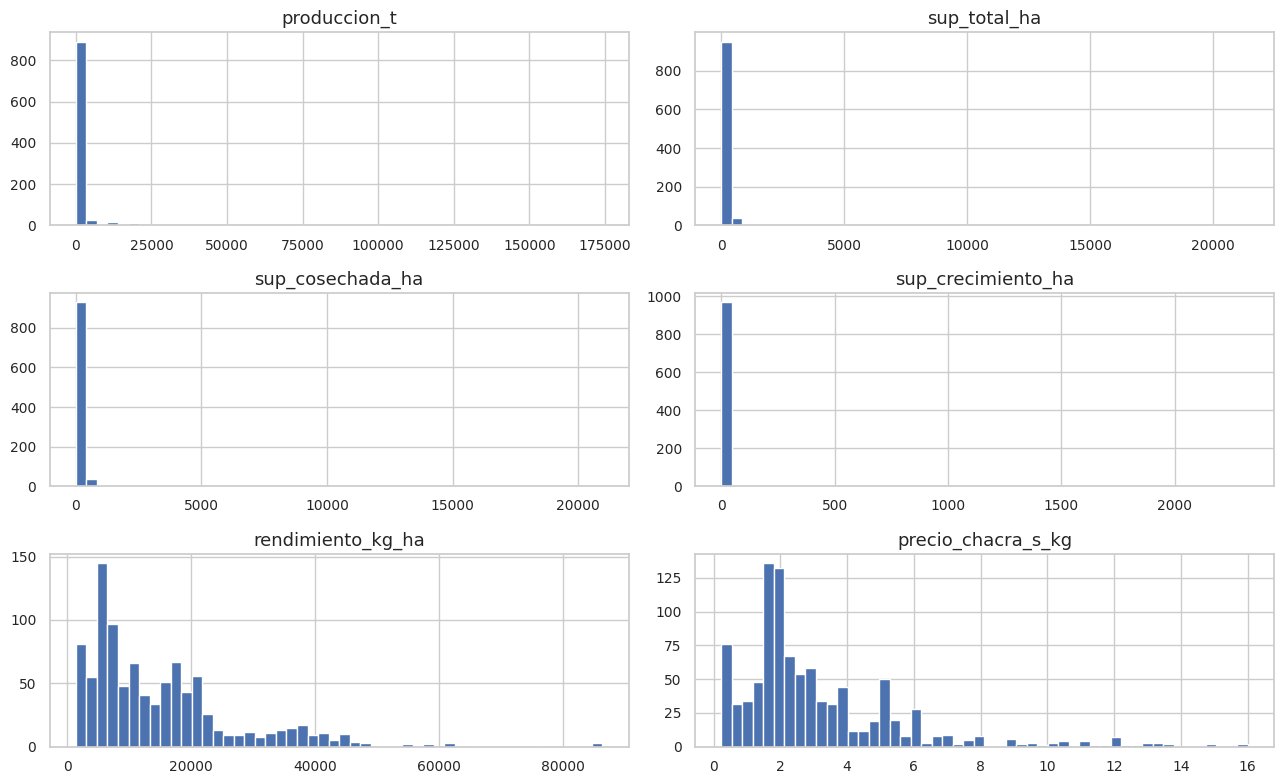

In [10]:
num_cols = ["produccion_t", "sup_total_ha", "sup_cosechada_ha", "sup_crecimiento_ha", "rendimiento_kg_ha", "precio_chacra_s_kg"]
agri[num_cols].hist(bins=50, figsize=(13, 8))
plt.tight_layout(); plt.show()

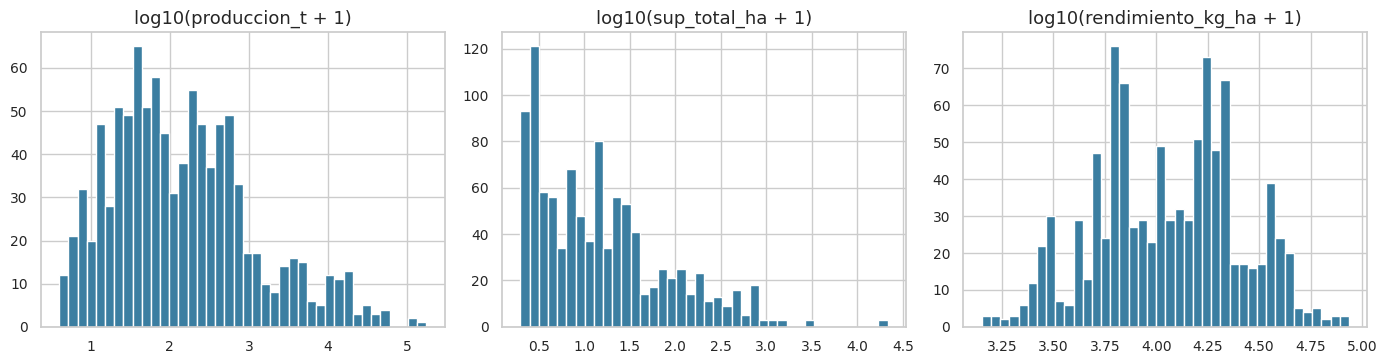

Asimetría (skew):
produccion_t          11.40
sup_total_ha          17.24
sup_cosechada_ha      17.06
sup_crecimiento_ha    24.37
rendimiento_kg_ha      1.81
precio_chacra_s_kg     2.02


In [11]:
# Misma información en escala logarítmica para variables de cola larga
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axes, ["produccion_t", "sup_total_ha", "rendimiento_kg_ha"]):
    ax.hist(np.log10(agri[c].dropna() + 1), bins=40, color="#3b7ea1")
    ax.set_title(f"log10({c} + 1)")
plt.tight_layout(); plt.show()
print("Asimetría (skew):"); print(agri[num_cols].skew().round(2).to_string())

### Actividad 4 — Interpretación de distribuciones
1. Elige dos histogramas de forma distinta y compáralos (simetría, concentración, colas).
2. ¿Qué variables tienen cola larga a la derecha? Relaciónalo con la mezcla de cultivos grandes (alfalfa, maíz chala) y pequeños.
3. ¿Qué efecto tiene el logaritmo sobre la forma? ¿Por qué podría ayudar a un modelo lineal?
4. `sup_crecimiento_ha` tiene casi todo en cero: ¿qué significa eso agronómicamente?

**Respuestas:** _(completar)_

### 3.2 Rendimiento por tipo de cultivo, cultivo y provincia

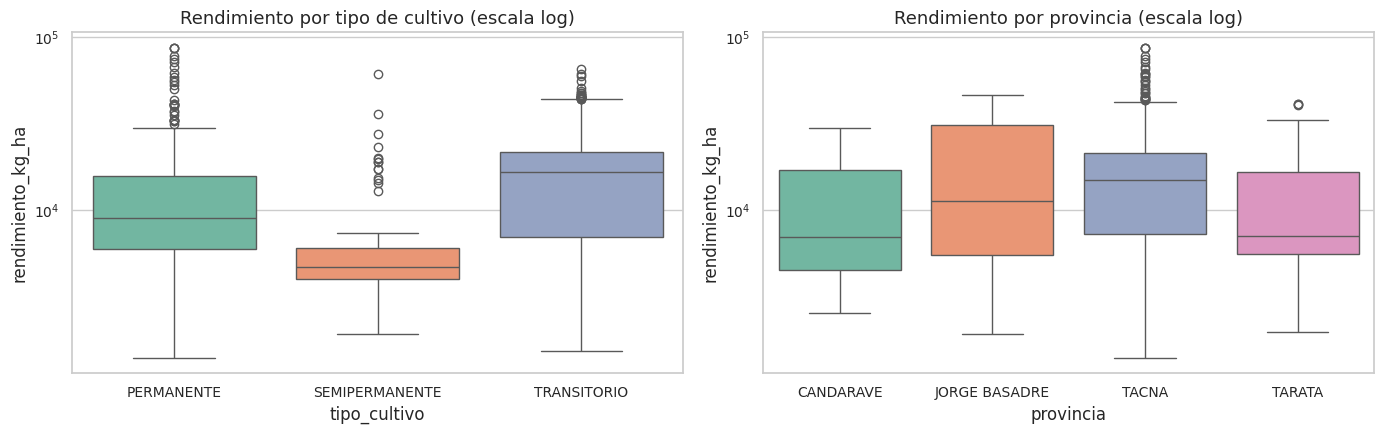

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=agri, x="tipo_cultivo", y="rendimiento_kg_ha", ax=axes[0], palette="Set2")
axes[0].set_yscale("log"); axes[0].set_title("Rendimiento por tipo de cultivo (escala log)")
sns.boxplot(data=agri, x="provincia", y="rendimiento_kg_ha", ax=axes[1], palette="Set2")
axes[1].set_yscale("log"); axes[1].set_title("Rendimiento por provincia (escala log)")
plt.tight_layout(); plt.show()

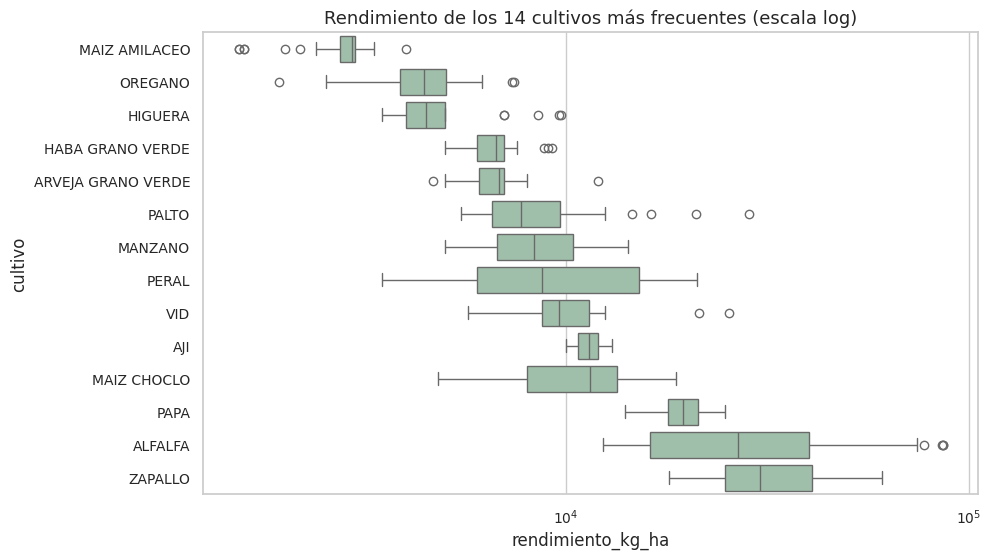

In [13]:
top = agri["cultivo"].value_counts().head(14).index
orden = agri[agri["cultivo"].isin(top)].groupby("cultivo")["rendimiento_kg_ha"].median().sort_values().index
plt.figure(figsize=(10, 6))
sns.boxplot(data=agri[agri["cultivo"].isin(top)], y="cultivo", x="rendimiento_kg_ha", order=orden, color="#9bc4a8")
plt.xscale("log"); plt.title("Rendimiento de los 14 cultivos más frecuentes (escala log)")
plt.show()

### Actividad 5 — ¿Cuánto del rendimiento lo explica el cultivo?
1. Ordena los cultivos por mediana de rendimiento. ¿Qué cultivos rinden más y cuáles menos? ¿Es comparable el rendimiento de la alfalfa con el de la quinua (¿por qué no?).
2. ¿Hay diferencias entre provincias? Antes de atribuirlas al territorio, ¿qué otra cosa varía entre provincias?
3. **Hipótesis (no prueba):** ¿qué explicaría que el cultivo domine la variabilidad del rendimiento?

**Respuestas:** _(completar)_

### 3.3 Rendimiento relativo al cultivo y efecto del año
Para comparar distritos y años sin que el tipo de cultivo domine, se define el **rendimiento relativo** = rendimiento ÷ mediana del rendimiento de ese cultivo (valor 1 = rinde como la mediana). Se usa solo en el análisis descriptivo; **no** es una variable predictora porque contiene la variable objetivo.

34 cultivos con al menos 10 registros; 875 filas


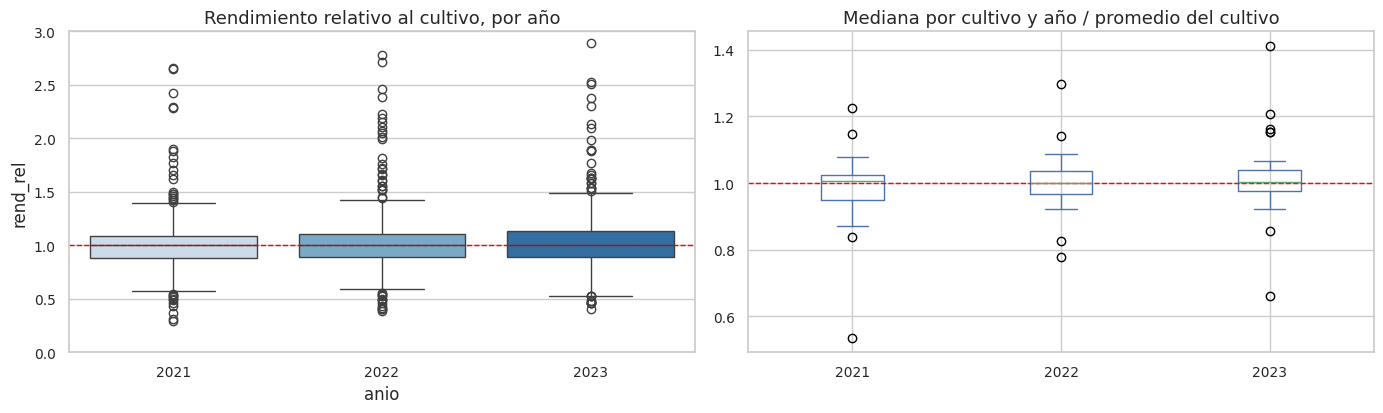

Mediana del rendimiento relativo por año:
anio
2021    1.000
2022    1.000
2023    1.002

Prueba de Kruskal–Wallis entre años: H = 1.02, p = 0.600


In [14]:
FREQ_MIN = 10
n_cult = agri["cultivo"].value_counts()
cult_ok = n_cult[n_cult >= FREQ_MIN].index
eda = agri[agri["cultivo"].isin(cult_ok) & agri["rendimiento_kg_ha"].notna()].copy()
eda["rend_rel"] = eda["rendimiento_kg_ha"] / eda.groupby("cultivo")["rendimiento_kg_ha"].transform("median")
print(f"{len(cult_ok)} cultivos con al menos {FREQ_MIN} registros; {len(eda)} filas")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
sns.boxplot(data=eda, x="anio", y="rend_rel", ax=axes[0], palette="Blues")
axes[0].axhline(1, color="red", ls="--", lw=1); axes[0].set_ylim(0, 3)
axes[0].set_title("Rendimiento relativo al cultivo, por año")
piv_year = eda.pivot_table(index="cultivo", columns="anio", values="rendimiento_kg_ha", aggfunc="median")
(piv_year.div(piv_year.mean(axis=1), axis=0)).plot(kind="box", ax=axes[1])
axes[1].axhline(1, color="red", ls="--", lw=1); axes[1].set_title("Mediana por cultivo y año / promedio del cultivo")
plt.tight_layout(); plt.show()

print("Mediana del rendimiento relativo por año:"); print(eda.groupby("anio")["rend_rel"].median().round(3).to_string())
H, p = st.kruskal(*[g["rend_rel"].values for _, g in eda.groupby("anio")])
print(f"\nPrueba de Kruskal–Wallis entre años: H = {H:.2f}, p = {p:.3f}")

### Actividad 6 — ¿Influye el periodo 2021–2023?
1. ¿Se observan diferencias de rendimiento relativo entre 2021, 2022 y 2023? ¿Son grandes frente a la diferencia entre cultivos?
2. Interpreta la prueba de Kruskal–Wallis (qué compara, qué significa el valor *p*) **sin** atribuir la causa a la pandemia: con tres años no se puede separar el efecto de la pandemia del de otros factores (precios de insumos, clima, etc.).
3. ¿Qué limitación declararías en el informe sobre usar solo tres campañas?

**Respuestas:** _(completar)_

### 3.4 Panorama por distrito
No hay coordenadas en el anuario, de modo que en lugar del mapa del laboratorio se describe el espacio con gráficos por distrito y una matriz distrito × cultivo.

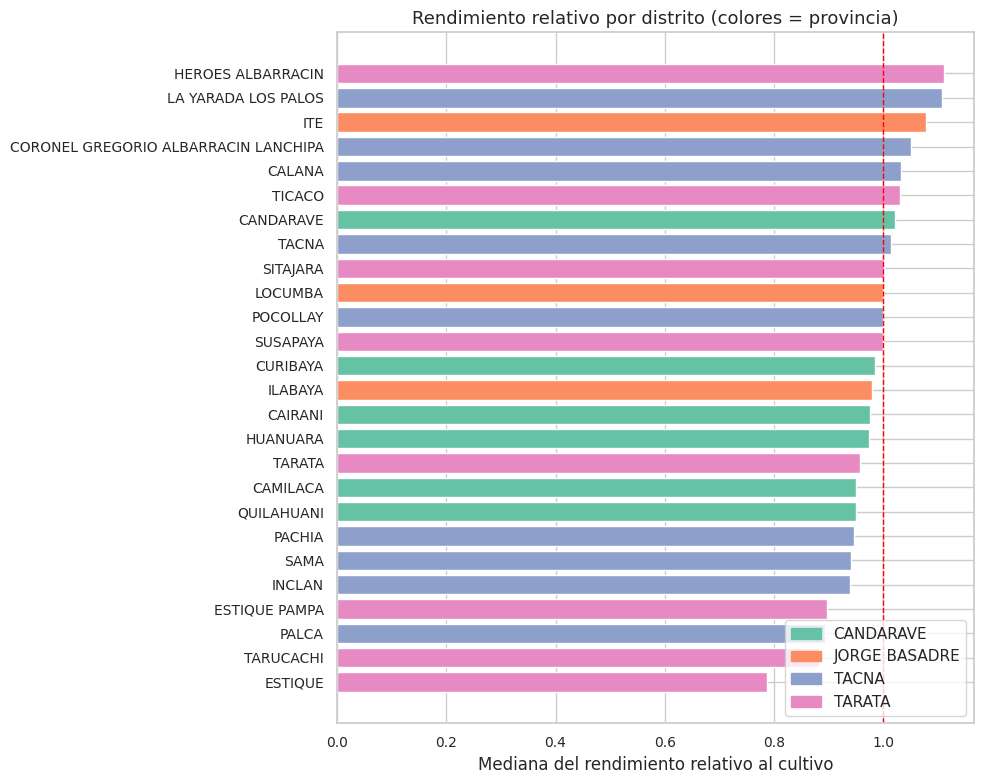

In [15]:
dist_tab = (eda.groupby(["provincia", "distrito"])
              .agg(n=("rend_rel", "size"), rend_rel_mediana=("rend_rel", "median"), sup_ha=("sup_total_ha", "sum"))
              .reset_index().sort_values("rend_rel_mediana"))
fig, ax = plt.subplots(figsize=(10, 8))
cols = dist_tab["provincia"].map(dict(zip(sorted(dist_tab.provincia.unique()), sns.color_palette("Set2", 4))))
ax.barh(dist_tab["distrito"], dist_tab["rend_rel_mediana"], color=cols)
ax.axvline(1, color="red", ls="--", lw=1)
ax.set_xlabel("Mediana del rendimiento relativo al cultivo"); ax.set_title("Rendimiento relativo por distrito (colores = provincia)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in sns.color_palette("Set2", 4)]
ax.legend(handles, sorted(dist_tab.provincia.unique()), loc="lower right")
plt.tight_layout(); plt.show()

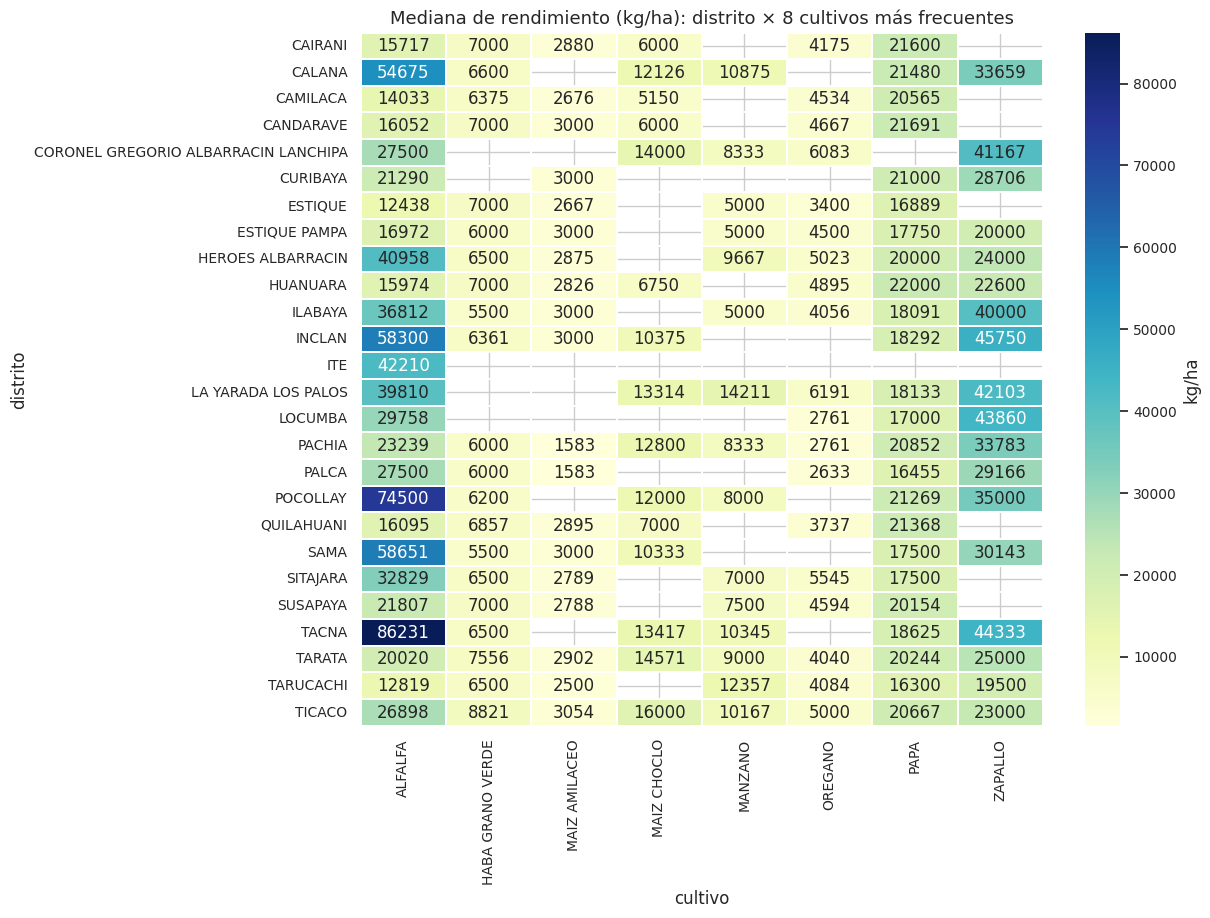

In [16]:
top8 = agri["cultivo"].value_counts().head(8).index
mat = agri[agri["cultivo"].isin(top8)].pivot_table(index="distrito", columns="cultivo", values="rendimiento_kg_ha", aggfunc="median")
plt.figure(figsize=(11, 9))
sns.heatmap(mat, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "kg/ha"}, linewidths=.3)
plt.title("Mediana de rendimiento (kg/ha): distrito × 8 cultivos más frecuentes"); plt.show()

### Actividad 7 — Patrón espacial
1. ¿Qué distritos o provincias tienen rendimiento relativo por debajo de 1 y cuáles por encima?
2. En la matriz distrito × cultivo, ¿hay cultivos que solo existen en algunas zonas? ¿Qué implica eso para comparar distritos?
3. Un gráfico no demuestra causas. Propón **dos factores externos** (por ejemplo, altitud, disponibilidad de agua, tecnificación del riego) que podrían explicar las diferencias y distingue claramente *información externa* de *observaciones del gráfico*, citando fuente.

**Respuestas:** _(completar)_

### 3.5 Relaciones entre variables numéricas

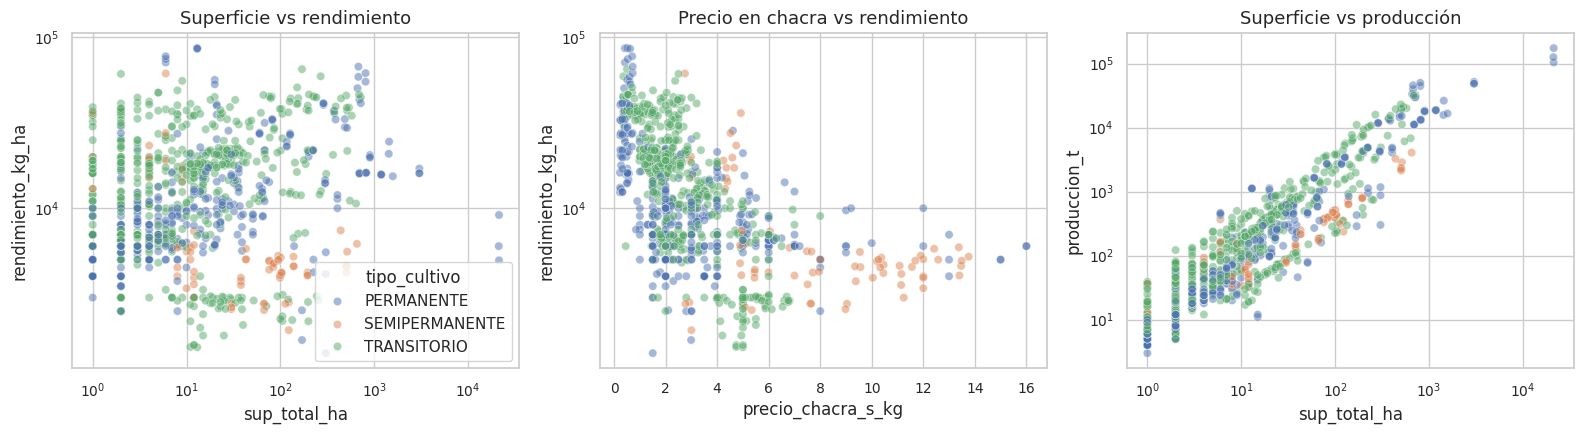

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(data=agri, x="sup_total_ha", y="rendimiento_kg_ha", hue="tipo_cultivo", alpha=.5, ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_title("Superficie vs rendimiento")
sns.scatterplot(data=agri, x="precio_chacra_s_kg", y="rendimiento_kg_ha", hue="tipo_cultivo", alpha=.5, ax=axes[1], legend=False)
axes[1].set_yscale("log"); axes[1].set_title("Precio en chacra vs rendimiento")
sns.scatterplot(data=agri, x="sup_total_ha", y="produccion_t", hue="tipo_cultivo", alpha=.5, ax=axes[2], legend=False)
axes[2].set_xscale("log"); axes[2].set_yscale("log"); axes[2].set_title("Superficie vs producción")
plt.tight_layout(); plt.show()

### Actividad 8 — Lectura de los diagramas de dispersión
1. ¿Qué relación observas entre precio en chacra y rendimiento? ¿Es una relación causal o está mediada por el tipo de cultivo?
2. ¿Por qué la relación superficie–producción es casi una línea recta en escala logarítmica, y qué sentido tiene eso dado que rendimiento = producción / superficie?
3. ¿Ves grupos o bandas horizontales? ¿Qué las explicaría (por ejemplo, valores de rendimiento que se repiten por redondeo en el registro)?

**Respuestas:** _(completar)_

## 4. Correlaciones

In [18]:
corr_pearson = agri.corr(numeric_only=True)
corr_spearman = agri.corr(numeric_only=True, method="spearman")
tabla_corr = pd.DataFrame({"Pearson": corr_pearson["rendimiento_kg_ha"], "Spearman": corr_spearman["rendimiento_kg_ha"]})
tabla_corr.sort_values("Pearson", ascending=False).round(3)

,Pearson,Spearman
rendimiento_kg_ha,1.000,1.000
produccion_t,0.193,0.571
anio,0.005,0.010
sup_cosechada_ha,-0.006,0.214
sup_total_ha,-0.007,0.210
sup_crecimiento_ha,-0.019,-0.071
precio_chacra_s_kg,-0.471,-0.632
en_crecimiento_sin_cosecha,NaN,NaN
distrito_inferido,NaN,NaN


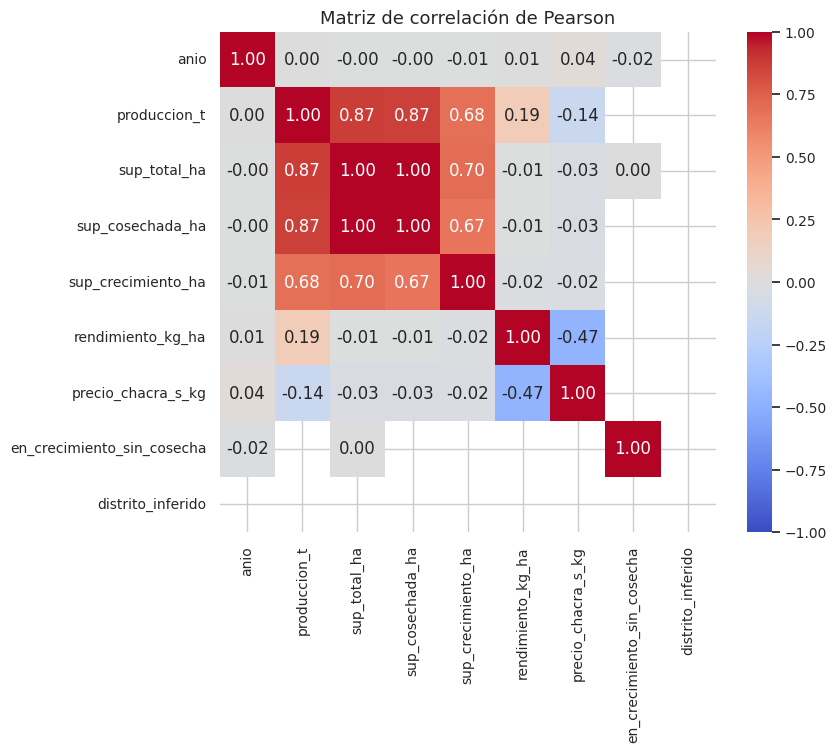

In [19]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlación de Pearson"); plt.show()

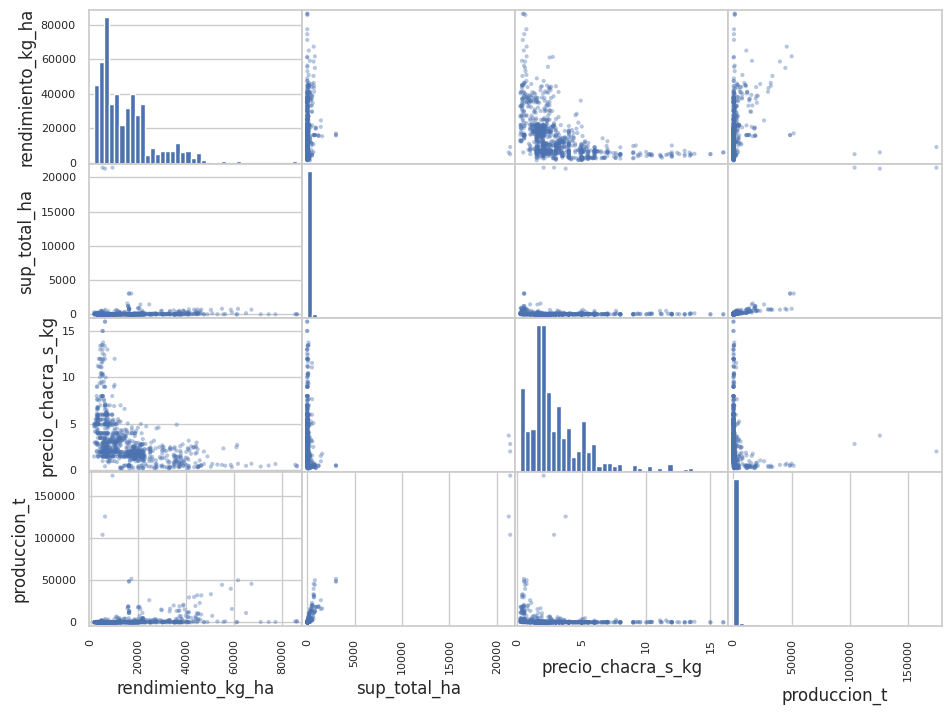

In [20]:
from pandas.plotting import scatter_matrix
attrs = ["rendimiento_kg_ha", "sup_total_ha", "precio_chacra_s_kg", "produccion_t"]
scatter_matrix(agri[attrs], figsize=(11, 8), alpha=.4, diagonal="hist", hist_kwds={"bins": 40})
plt.show()

### Actividad 9 — Ranking de correlaciones
1. Copia los coeficientes de Pearson de las variables con mayor correlación (positiva y negativa) con `rendimiento_kg_ha`.
2. Compara Pearson con Spearman: ¿en qué variables cambia más y por qué (relaciones monótonas no lineales, atípicos)?
3. `produccion_t` y `sup_cosechada_ha` tienen correlaciones altas entre sí: ¿qué problema genera esto para un modelo lineal (multicolinealidad)?
4. La correlación de Pearson mide solo asociación lineal y no incluye variables categóricas. ¿Por qué esto subestima la importancia del cultivo?

**Respuestas:** _(completar)_

## 5. Atributos derivados (ingeniería de características)
Se construyen variables que **no contienen la variable objetivo**:

| Atributo | Definición | Hipótesis |
|---|---|---|
| `pct_crecimiento` | superficie en crecimiento ÷ superficie total | los cultivos con mucha superficie nueva todavía no rinden igual |
| `ln_sup_total` | log(1 + superficie total) | la superficie tiene cola larga; el log estabiliza la escala |
| `part_sup_distrito` | superficie del cultivo ÷ superficie total del distrito en ese año | los cultivos dominantes del distrito reciben más manejo técnico |
| `n_cultivos_distrito` | número de cultivos distintos del distrito en ese año | diversificación como indicador de tecnificación/mercado |

In [21]:
d = agri.copy()
d["sup_crecimiento_ha"] = d["sup_total_ha"] - d["sup_cosechada_ha"]
d["pct_crecimiento"] = d["sup_crecimiento_ha"] / d["sup_total_ha"]
d["ln_sup_total"] = np.log1p(d["sup_total_ha"])
d["part_sup_distrito"] = d["sup_total_ha"] / d.groupby(["anio", "distrito"])["sup_total_ha"].transform("sum")
d["n_cultivos_distrito"] = d.groupby(["anio", "distrito"])["cultivo"].transform("nunique")
d["anio_cat"] = d["anio"].astype(str)

derivadas = ["pct_crecimiento", "ln_sup_total", "part_sup_distrito", "n_cultivos_distrito"]
orig = ["sup_total_ha", "precio_chacra_s_kg"]
comp = pd.DataFrame({
    "Pearson": d[derivadas + orig].corrwith(d["rendimiento_kg_ha"]),
    "Spearman": d[derivadas + orig].corrwith(d["rendimiento_kg_ha"], method="spearman")}).round(3)
comp

,Pearson,Spearman
pct_crecimiento,-0.073,-0.070
ln_sup_total,0.227,0.210
part_sup_distrito,0.118,0.092
n_cultivos_distrito,0.195,0.218
sup_total_ha,-0.007,0.210
precio_chacra_s_kg,-0.471,-0.632


### Actividad 10 — Evaluar los atributos derivados
1. Explica con tus palabras qué mide cada atributo derivado y en qué unidades se interpreta.
2. Compara su correlación con la de las variables originales. ¿Alguna derivada es más informativa? Sustenta con valores.
3. ¿Por qué una razón o un porcentaje puede ser más útil que un total absoluto?
4. Cada atributo se calcula con datos de otras filas del mismo distrito-año (no con el rendimiento): ¿por qué eso **no** es fuga de información, pero sí obligaría a cuidar la división de los datos?

**Respuestas:** _(completar)_

## 6. Unidad 01 — Preprocesamiento y tabla analítica
### 6.1 Valores faltantes: mecanismo y técnica de imputación
- **Rendimiento / producción / superficie cosechada (27 filas):** faltante *estructural* (cultivos en crecimiento aún sin cosecha). No se imputa: no existe un rendimiento que predecir. Se excluyen del modelado, **no** se reemplazan por cero.
- **Precio en chacra (1 fila con rendimiento):** faltante *accidental*; es un candidato a imputación.

Para decidir *cómo* imputar se **simula** un faltante completamente al azar (MCAR) del 10 % sobre los precios conocidos y se compara qué técnica recupera mejor el valor verdadero.

In [22]:
base = d.dropna(subset=["rendimiento_kg_ha"]).copy()
conocidos = base.dropna(subset=["precio_chacra_s_kg"]).reset_index(drop=True)
print(f"Filas modelables: {len(base)} | con precio conocido: {len(conocidos)}")

def imputar(df, mask, metodo):
    precio = df["precio_chacra_s_kg"].copy(); precio[mask] = np.nan
    if metodo == "mediana global":
        return precio.fillna(precio.median())
    if metodo == "mediana por cultivo":
        med = precio.groupby(df["cultivo"]).transform("median")
        return precio.fillna(med).fillna(precio.median())
    if metodo == "KNN (k=5, numéricas)":
        Z = pd.DataFrame({"p": precio, "a": df["ln_sup_total"], "b": df["part_sup_distrito"],
                          "c": df["pct_crecimiento"].fillna(0)})
        Z = (Z - Z.mean()) / Z.std()
        return pd.Series(KNNImputer(n_neighbors=5).fit_transform(Z)[:, 0] * (precio.std()) + precio.mean(), index=df.index)

res = []
for seed in range(30):
    rng = np.random.default_rng(seed)
    mask = rng.random(len(conocidos)) < 0.10
    for m in ["mediana global", "mediana por cultivo", "KNN (k=5, numéricas)"]:
        est = imputar(conocidos, mask, m)[mask]
        real = conocidos.loc[mask, "precio_chacra_s_kg"]
        res.append(dict(metodo=m, MAE=mean_absolute_error(real, est), RMSE=np.sqrt(mean_squared_error(real, est))))
res = pd.DataFrame(res).groupby("metodo").mean().round(3).sort_values("RMSE")
res

Filas modelables: 978 | con precio conocido: 977


,MAE,RMSE
metodo,,
mediana por cultivo,0.634,1.143
"KNN (k=5, numéricas)",1.546,2.219
mediana global,1.663,2.623


**Decisión:** se imputa el precio con la **mediana del cultivo** (calculada solo con los datos de entrenamiento, dentro del *pipeline*), porque es la técnica que mejor recupera el valor verdadero en la simulación.

### Actividad 11 — Faltantes
1. Clasifica cada faltante como MCAR, MAR, MNAR o estructural y justifica.
2. ¿Por qué la imputación debe calcularse **solo con el conjunto de entrenamiento**?
3. ¿Qué pasaría con el tamaño y la representatividad de la muestra si se eliminaran todas las filas con algún faltante?

**Respuestas:** _(completar)_

### 6.2 Variables categóricas y su codificación
Todas las categóricas son **nominales** (cultivo, tipo de cultivo, provincia, distrito, año). Se codifican con *one-hot*: una columna 0/1 por categoría. Las categorías con menos de 5 registros se agrupan como "poco frecuentes" para evitar columnas casi vacías y se ignoran las categorías desconocidas al predecir.

In [23]:
cat_demo = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False)
cat_demo.fit(base[["cultivo", "tipo_cultivo", "provincia", "distrito", "anio_cat"]])
print("Columnas tras one-hot:", len(cat_demo.get_feature_names_out()))
print("Categorías de 'cultivo' agrupadas como poco frecuentes:",
      int((base["cultivo"].value_counts() < 5).sum()), "de", base["cultivo"].nunique())

Columnas tras one-hot: 82
Categorías de 'cultivo' agrupadas como poco frecuentes: 12 de 57


### 6.3 Valores atípicos: detección y decisión
Se aplican dos criterios sobre el rendimiento: **rango intercuartílico** (fuera de [Q1 − 1,5·RIC, Q3 + 1,5·RIC]) y **puntuación z** (|z| > 3). Como los cultivos son muy distintos, se aplican también **dentro de cada cultivo**.

In [24]:
def mask_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); r = q3 - q1
    return (s < q1 - k * r) | (s > q3 + k * r)

y = base["rendimiento_kg_ha"]
glob_iqr = mask_iqr(y); glob_z = (np.abs(st.zscore(y)) > 3)
cultivos_n = base["cultivo"].map(base["cultivo"].value_counts())
by_iqr = base.groupby("cultivo")["rendimiento_kg_ha"].transform(lambda s: mask_iqr(s) if len(s) >= 8 else pd.Series(False, index=s.index))
by_z = base.groupby("cultivo")["rendimiento_kg_ha"].transform(lambda s: (np.abs((s - s.mean()) / s.std(ddof=0)) > 3) if len(s) >= 8 else pd.Series(False, index=s.index))
tabla_at = pd.DataFrame({"IQR global": [glob_iqr.sum()], "z global": [glob_z.sum()],
                         "IQR por cultivo": [int(by_iqr.sum())], "z por cultivo": [int(by_z.sum())]}, index=["n filas"])
tabla_at

,IQR global,z global,IQR por cultivo,z por cultivo
n filas,42,16,54,7


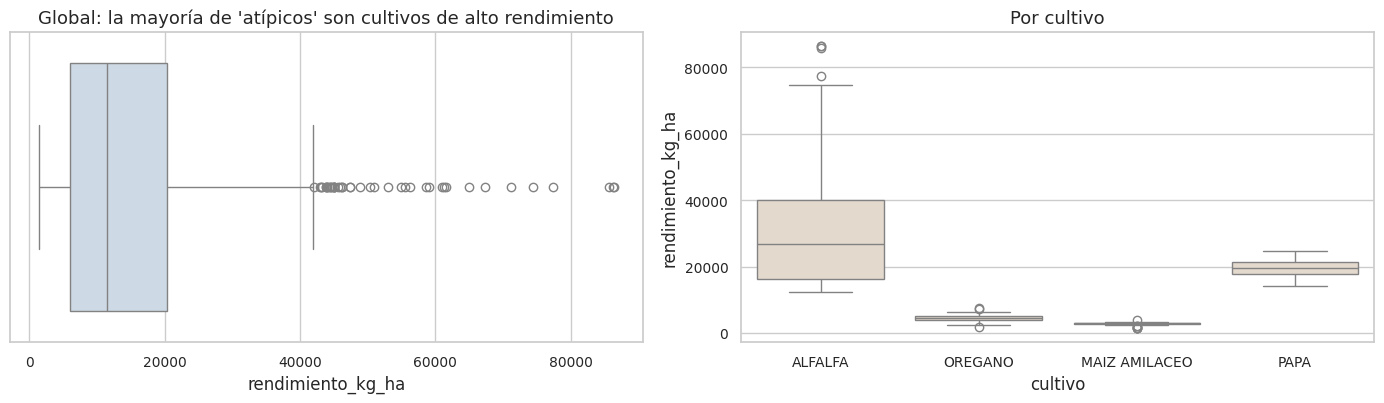

Principales atípicos dentro del cultivo (IQR):


,anio,distrito,cultivo,rendimiento_kg_ha,mediana_cultivo,razon
700,2023,ILABAYA,MAIZ AMILACEO,4000.0,1583.0,2.53
446,2022,LA YARADA LOS PALOS,PALTO,28400.0,18625.0,1.52
582,2022,ESTIQUE,ARVEJA GRANO VERDE,12000.0,8333.5,1.44
927,2023,ESTIQUE,MAIZ AMILACEO,2182.0,1583.0,1.38
600,2022,HEROES ALBARRACIN,MEMBRILLO,22333.0,17333.0,1.29
101,2021,LA YARADA LOS PALOS,ROCOTO,61333.0,48666.5,1.26
987,2023,TARUCACHI,MAIZ AMILACEO,2000.0,1583.0,1.26
226,2021,TACNA,TOMATE,55556.0,48875.0,1.14
441,2022,LA YARADA LOS PALOS,HIGUERA,9700.0,8500.0,1.14
788,2023,LA YARADA LOS PALOS,HIGUERA,9600.0,8500.0,1.13


In [25]:
base["atipico_cultivo"] = by_iqr.astype(bool)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.boxplot(x=y, ax=axes[0], color="#c9d9e8"); axes[0].set_title("Global: la mayoría de 'atípicos' son cultivos de alto rendimiento")
cv = base[base["cultivo"].isin(["ALFALFA", "PAPA", "OREGANO", "MAIZ AMILACEO"])]
sns.boxplot(data=cv, x="cultivo", y="rendimiento_kg_ha", ax=axes[1], color="#e8d9c9"); axes[1].set_title("Por cultivo")
plt.tight_layout(); plt.show()
print("Principales atípicos dentro del cultivo (IQR):")
base[base["atipico_cultivo"]].assign(mediana_cultivo=lambda x: x.groupby("cultivo")["rendimiento_kg_ha"].transform("median")) \
    .assign(razon=lambda x: (x.rendimiento_kg_ha / x.mediana_cultivo).round(2)) \
    .sort_values("razon", ascending=False)[["anio", "distrito", "cultivo", "rendimiento_kg_ha", "mediana_cultivo", "razon"]].head(10)

**Decisión sobre atípicos.** Los valores extremos del análisis global son sobre todo cultivos de alto rendimiento por naturaleza (alfalfa, maíz chala), no errores. Dentro de cada cultivo los atípicos son pocos y, además, **ya se comprobó que cada rendimiento coincide con producción ÷ superficie** (±10 %), así que no son errores de digitación. Por tanto **se conservan**, y se mide más adelante la sensibilidad del modelo a su presencia (sección 7.9).

### Actividad 12 — Atípicos
1. ¿Por qué detectar atípicos *globalmente* sería un error en este conjunto?
2. ¿Qué diferencia hay entre un valor atípico y un error de registro? ¿Cómo lo verificaste?
3. Justifica tu decisión de conservarlos y menciona un riesgo.

**Respuestas:** _(completar)_

### 6.4 Escalamiento
Los modelos lineales, polinómicos y K-NN son sensibles a la escala de las variables; los árboles y bosques no. Se usa **estandarización** (media 0, desviación 1) calculada con el entrenamiento.

### 6.5 División entrenamiento / prueba
Los datos **no** son una serie de tiempo (cada fila es un cultivo en un distrito y año), por eso la división puede ser aleatoria: 80 % entrenamiento y 20 % prueba, estratificada por tipo de cultivo.  
**Variables predictoras:** solo las que no contienen la respuesta. Se excluyen `produccion_t` y `sup_cosechada_ha` porque, junto con el rendimiento, reconstruyen la fórmula rendimiento = producción ÷ superficie (fuga de información).

In [26]:
FEATURES_NUM = ["ln_sup_total", "pct_crecimiento", "precio_chacra_s_kg", "part_sup_distrito", "n_cultivos_distrito"]
FEATURES_CAT = ["cultivo", "tipo_cultivo", "provincia", "distrito", "anio_cat"]
TARGET = "rendimiento_kg_ha"

X = base[FEATURES_NUM + FEATURES_CAT]; y = base[TARGET]
grupos = base["distrito"] + "|" + base["cultivo"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=base["tipo_cultivo"])
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("\nRendimiento (kg/ha) en cada partición:")
pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(0)

Entrenamiento: (782, 10) | Prueba: (196, 10)

Rendimiento (kg/ha) en cada partición:


,train,test
count,782.0,196.0
mean,15522.0,15252.0
std,13108.0,11709.0
min,1538.0,1420.0
25%,6000.0,6938.0
50%,11500.0,11834.0
75%,20361.0,20574.0
max,86385.0,74500.0


In [27]:
# Escalamiento: antes y después (solo con datos de entrenamiento)
sc = StandardScaler().fit(X_train[FEATURES_NUM].fillna(X_train[FEATURES_NUM].median()))
despues = pd.DataFrame(sc.transform(X_test[FEATURES_NUM].fillna(X_train[FEATURES_NUM].median())), columns=FEATURES_NUM)
print("Prueba — ANTES del escalamiento:"); print(X_test[FEATURES_NUM].describe().loc[["mean", "std"]].round(2).to_string())
print("\nPrueba — DESPUÉS (ajustado con entrenamiento):"); print(despues.describe().loc[["mean", "std"]].round(2).to_string())

Prueba — ANTES del escalamiento:
      ln_sup_total  pct_crecimiento  precio_chacra_s_kg  part_sup_distrito  n_cultivos_distrito
mean          2.62             0.02                3.01               0.06                19.33
std           1.49             0.10                2.38               0.12                 9.75

Prueba — DESPUÉS (ajustado con entrenamiento):
      ln_sup_total  pct_crecimiento  precio_chacra_s_kg  part_sup_distrito  n_cultivos_distrito
mean         -0.09            -0.08               -0.05              -0.07                -0.01
std           0.90             0.82                0.92               0.77                 0.98


### 6.6 Tabla analítica final
La tabla analítica reúne las variables predictoras construidas, la variable objetivo y los identificadores. El preprocesamiento que depende de los datos (imputación, escalamiento, codificación) se ajusta **dentro** de un *pipeline* solo con el entrenamiento.

In [28]:
tabla_analitica = base[["anio", "provincia", "distrito", "tipo_cultivo", "cultivo"] + FEATURES_NUM + [TARGET]].copy()
tabla_analitica.to_csv("tabla_analitica_final.csv", index=False, encoding="utf-8-sig")
print("Tabla analítica:", tabla_analitica.shape)
tabla_analitica.head()

Tabla analítica: (978, 11)


,anio,provincia,distrito,tipo_cultivo,cultivo,ln_sup_total,pct_crecimiento,precio_chacra_s_kg,part_sup_distrito,n_cultivos_distrito,rendimiento_kg_ha
0,2021,CANDARAVE,CAIRANI,PERMANENTE,ALFALFA,7.080026,0.0,0.46,0.879911,5,15705.0
1,2021,CANDARAVE,CAIRANI,SEMIPERMANENTE,OREGANO,4.644391,0.0,10.45,0.076353,5,4175.0
2,2021,CANDARAVE,CAIRANI,TRANSITORIO,HABA GRANO VERDE,1.386294,0.0,1.67,0.002224,5,7000.0
3,2021,CANDARAVE,CAIRANI,TRANSITORIO,MAIZ AMILACEO,3.258097,0.0,5.60,0.018532,5,3000.0
4,2021,CANDARAVE,CAIRANI,TRANSITORIO,PAPA,3.465736,0.0,1.56,0.022980,5,22032.0


In [29]:
dic = pd.DataFrame({
    "variable": tabla_analitica.columns,
    "tipo": [str(t) for t in tabla_analitica.dtypes],
    "rol": ["id", "id", "id", "predictora (cat.)", "predictora (cat.)"] + ["predictora (num.)"] * 5 + ["objetivo"],
    "n_faltantes": tabla_analitica.isna().sum().values})
dic

,variable,tipo,rol,n_faltantes
0,anio,int64,id,0
1,provincia,str,id,0
2,distrito,str,id,0
3,tipo_cultivo,str,predictora (cat.),0
4,cultivo,str,predictora (cat.),0
5,ln_sup_total,float64,predictora (num.),0
6,pct_crecimiento,float64,predictora (num.),0
7,precio_chacra_s_kg,float64,predictora (num.),1
8,part_sup_distrito,float64,predictora (num.),0
9,n_cultivos_distrito,int64,predictora (num.),0


### Actividad 13 — Cierre de la Unidad 01
1. Resume en una tabla las decisiones de preprocesamiento (faltantes, categóricas, atípicos, escalamiento, división) con su justificación.
2. ¿Qué filas y columnas se descartaron y por qué (distritos inferidos, filas sin cosecha, `produccion_t`, `sup_cosechada_ha`)?
3. ¿Qué es la fuga de información y en qué dos puntos de este notebook se previno?

**Respuestas:** _(completar)_

## 7. Unidad 02 — Modelos de regresión
**Plan:** línea base → regresión lineal múltiple → polinómica → árbol de regresión → bosque aleatorio.  
Los hiperparámetros (grado, profundidad, etc.) se eligen con **validación cruzada de 5 pliegues solo sobre el entrenamiento**; el conjunto de prueba se usa una sola vez para el informe final.  
**Métricas:** MAE (error típico en kg/ha), RMSE (penaliza errores grandes) y R² (proporción de varianza explicada).

In [30]:
class ImputaMedianaPorCultivo(BaseEstimator, TransformerMixin):
    """Imputa el precio con la mediana de su cultivo, calculada solo con los datos de ajuste."""
    def __init__(self, col="precio_chacra_s_kg", grupo="cultivo"):
        self.col = col; self.grupo = grupo
    def fit(self, X, y=None):
        self.med_ = X.groupby(self.grupo)[self.col].median()
        self.glob_ = X[self.col].median()
        return self
    def transform(self, X):
        X = X.copy()
        X[self.col] = X[self.col].fillna(X[self.grupo].map(self.med_)).fillna(self.glob_)
        return X

class MediaPorCultivo(BaseEstimator, RegressorMixin):
    """Línea base 2: predice la media de entrenamiento del cultivo (o la media global si es nuevo)."""
    def fit(self, X, y):
        self.med_ = pd.Series(np.asarray(y), index=X["cultivo"].values).groupby(level=0).mean()
        self.glob_ = float(np.mean(y)); return self
    def predict(self, X):
        return X["cultivo"].map(self.med_).fillna(self.glob_).values

def build_pipeline(modelo, num=FEATURES_NUM, cat=FEATURES_CAT, escalar=True, grado=None, drop_first=False):
    pasos = []
    if escalar: pasos.append(("scaler", StandardScaler()))
    if grado: pasos.append(("poly", PolynomialFeatures(degree=grado, include_bias=False)))
    num_pipe = Pipeline(pasos) if pasos else "passthrough"
    ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False,
                        drop="first" if drop_first else None)
    prep = ColumnTransformer([("num", num_pipe, num), ("cat", ohe, cat)])
    return Pipeline([("imp", ImputaMedianaPorCultivo()), ("prep", prep), ("modelo", modelo)])

KF = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
def cv_rmse(pipe, Xa, ya): return -cross_val_score(pipe, Xa, ya, cv=KF, scoring="neg_root_mean_squared_error").mean()

resultados = []
def evaluar(nombre, modelo):
    modelo.fit(X_train, y_train)
    ptr, pte = modelo.predict(X_train), modelo.predict(X_test)
    fila = dict(Modelo=nombre,
                MAE_train=mean_absolute_error(y_train, ptr), RMSE_train=rmse(y_train, ptr), R2_train=r2_score(y_train, ptr),
                MAE_test=mean_absolute_error(y_test, pte), RMSE_test=rmse(y_test, pte), R2_test=r2_score(y_test, pte))
    resultados.append(fila); return modelo
print("Funciones listas.")

Funciones listas.


### 7.1 Línea base
Todo modelo debe superar a una referencia simple. Se usan dos:  
(a) predecir siempre **la media** del entrenamiento; (b) predecir **la media del cultivo**, una referencia mucho más exigente porque ya incorpora el efecto principal que vimos en el EDA.

In [31]:
base_media = evaluar("Línea base: media global", DummyRegressor(strategy="mean"))
base_cultivo = evaluar("Línea base: media por cultivo", MediaPorCultivo())
pd.DataFrame(resultados).set_index("Modelo").round(3)

,MAE_train,RMSE_train,R2_train,MAE_test,RMSE_test,R2_test
Modelo,,,,,,
Línea base: media global,9712.832,13099.762,0.000,8993.270,11681.775,-0.001
Línea base: media por cultivo,3324.793,6774.453,0.733,3155.635,5687.829,0.763


### 7.2 Regresión lineal múltiple (mínimos cuadrados ordinarios)
Variables numéricas estandarizadas y categóricas en *one-hot* (con la primera categoría como referencia).

In [32]:
lin = evaluar("Regresión lineal múltiple", build_pipeline(LinearRegression(), drop_first=True))
nombres = lin.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lin.named_steps["modelo"].coef_, index=nombres).sort_values()
print("Intercepto:", round(lin.named_steps["modelo"].intercept_, 1))
print("\nCoeficientes de las variables numéricas (por 1 desviación estándar):")
print(coefs[coefs.index.str.startswith("num__")].round(1).to_string())
print("\nMayores efectos de categorías (kg/ha respecto a la categoría de referencia):")
cc = coefs[coefs.index.str.startswith("cat__")]
print(pd.concat([cc.head(6), cc.tail(6)]).round(0).to_string())

Intercepto: -1274.9

Coeficientes de las variables numéricas (por 1 desviación estándar):
num__part_sup_distrito     -5753.4
num__n_cultivos_distrito    -275.7
num__pct_crecimiento         532.2
num__precio_chacra_s_kg      589.6
num__ln_sup_total           3485.2

Mayores efectos de categorías (kg/ha respecto a la categoría de referencia):
cat__cultivo_QUINUA           -13967.0
cat__cultivo_FRIJOL VAINITA    -7626.0
cat__cultivo_MAIZ AMILACEO     -5816.0
cat__cultivo_OREGANO           -5420.0
cat__distrito_PACHIA           -1927.0
cat__distrito_PALCA            -1770.0
cat__cultivo_SANDIA            23351.0
cat__cultivo_CEBOLLA ROJA      23972.0
cat__cultivo_CEBOLLA           24301.0
cat__cultivo_TOMATE            25781.0
cat__cultivo_MAIZ CHALA        32500.0
cat__cultivo_ALFALFA           40777.0


### Actividad 14 — Interpretación de coeficientes
1. Interpreta el signo y la magnitud de dos coeficientes numéricos. ¿Qué significa "por una desviación estándar"?
2. Interpreta dos coeficientes de cultivo: ¿respecto a qué categoría están medidos?
3. ¿Qué supuestos del modelo lineal pueden estar fallando aquí (linealidad, varianza constante, multicolinealidad con muchas variables *dummy*)?

**Respuestas:** _(completar)_

### 7.3 Regresión polinómica: sobreajuste y subajuste
Se amplían las variables numéricas con potencias y productos hasta el grado *g*. Se grafica el error en entrenamiento, en validación cruzada y en prueba para observar el compromiso **sesgo–varianza**.

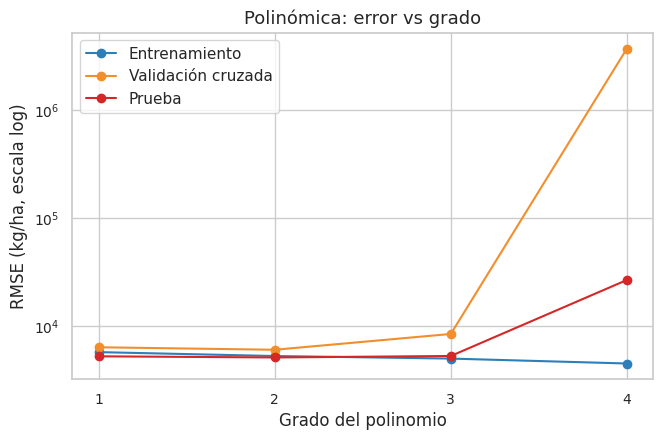

 grado  train        cv    test
     1 5745.0    6373.0  5254.0
     2 5287.0    6042.0  5126.0
     3 5005.0    8466.0  5290.0
     4 4507.0 3739233.0 26791.0

Grado elegido por validación cruzada: 2


In [33]:
curva = []
for g in range(1, 5):
    p = build_pipeline(LinearRegression(), grado=g, drop_first=True)
    p.fit(X_train, y_train)
    curva.append(dict(grado=g, train=rmse(y_train, p.predict(X_train)), cv=cv_rmse(p, X_train, y_train),
                      test=rmse(y_test, p.predict(X_test))))
curva = pd.DataFrame(curva)
plt.figure(figsize=(7.5, 4.5))
for c, col in zip(["train", "cv", "test"], ["#2c7fb8", "#f28e2b", "#d62728"]):
    plt.plot(curva["grado"], curva[c], "o-", label={"train": "Entrenamiento", "cv": "Validación cruzada", "test": "Prueba"}[c], color=col)
plt.yscale("log"); plt.xticks(curva["grado"]); plt.xlabel("Grado del polinomio"); plt.ylabel("RMSE (kg/ha, escala log)")
plt.title("Polinómica: error vs grado"); plt.legend(); plt.show()
GRADO_OPT = int(curva.loc[curva["cv"].idxmin(), "grado"])
print(curva.round(0).to_string(index=False)); print("\nGrado elegido por validación cruzada:", GRADO_OPT)
poly = evaluar(f"Regresión polinómica (grado {GRADO_OPT})", build_pipeline(LinearRegression(), grado=GRADO_OPT, drop_first=True))

### Actividad 15 — Sobreajuste
1. ¿Desde qué grado el error de prueba (o de validación) empieza a empeorar mientras el de entrenamiento sigue bajando? Eso es **sobreajuste**.
2. ¿Qué grado elegiste y con qué criterio (¿por qué no con el conjunto de prueba?)?
3. Explica con tus palabras el compromiso sesgo–varianza usando este gráfico.

**Respuestas:** _(completar)_

### 7.4 Árbol de regresión

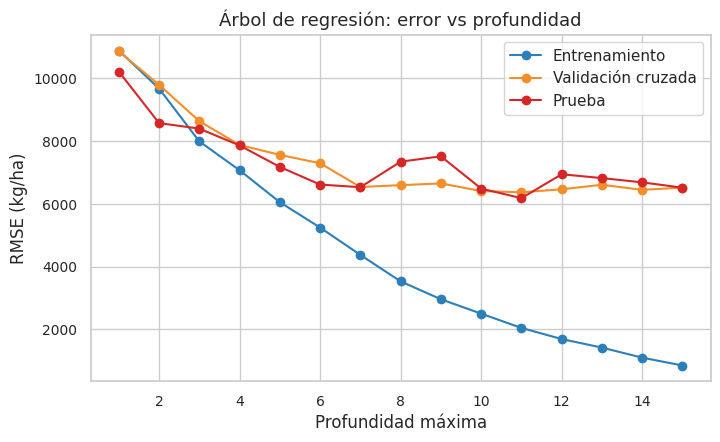

Profundidad elegida por validación cruzada: 11


In [34]:
curva_t = []
for prof in range(1, 16):
    p = build_pipeline(DecisionTreeRegressor(max_depth=prof, random_state=RANDOM_STATE), escalar=False)
    p.fit(X_train, y_train)
    curva_t.append(dict(profundidad=prof, train=rmse(y_train, p.predict(X_train)), cv=cv_rmse(p, X_train, y_train),
                        test=rmse(y_test, p.predict(X_test))))
curva_t = pd.DataFrame(curva_t)
plt.figure(figsize=(8, 4.5))
for c, col, lab in [("train", "#2c7fb8", "Entrenamiento"), ("cv", "#f28e2b", "Validación cruzada"), ("test", "#d62728", "Prueba")]:
    plt.plot(curva_t["profundidad"], curva_t[c], "o-", label=lab, color=col)
plt.xlabel("Profundidad máxima"); plt.ylabel("RMSE (kg/ha)"); plt.title("Árbol de regresión: error vs profundidad"); plt.legend(); plt.show()
PROF_OPT = int(curva_t.loc[curva_t["cv"].idxmin(), "profundidad"])
print("Profundidad elegida por validación cruzada:", PROF_OPT)
arbol = evaluar(f"Árbol de regresión (prof. {PROF_OPT})",
                build_pipeline(DecisionTreeRegressor(max_depth=PROF_OPT, random_state=RANDOM_STATE), escalar=False))

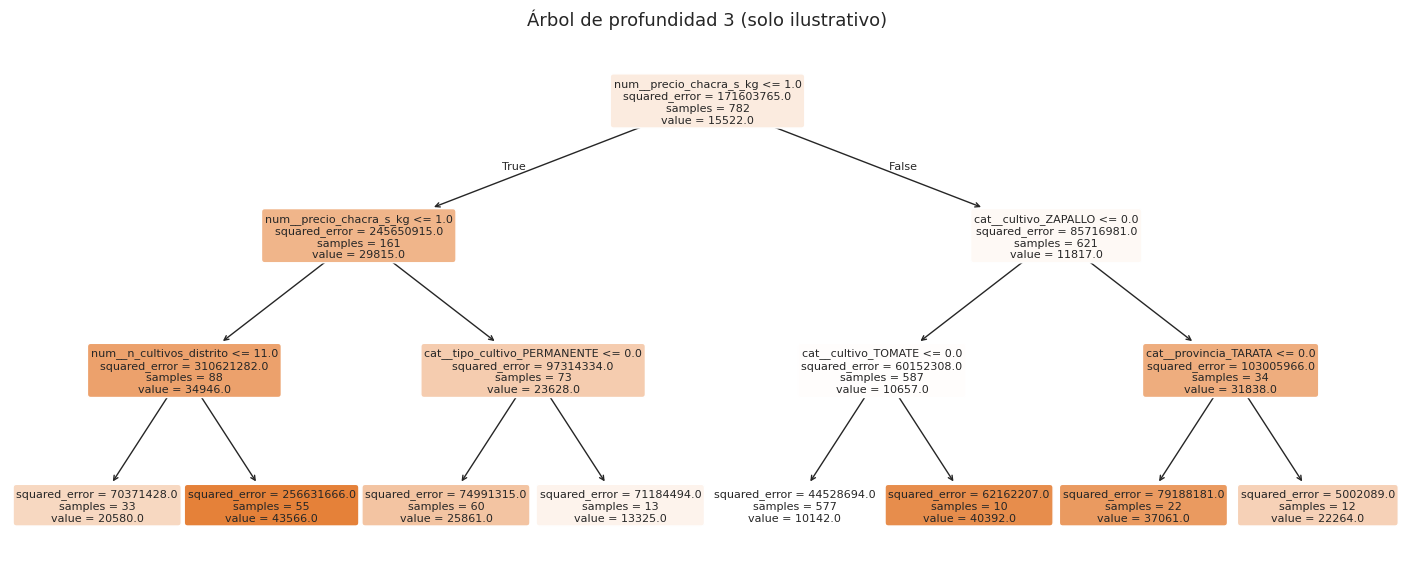

In [35]:
# Árbol pequeño solo para visualizar las reglas de partición
p3 = build_pipeline(DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE), escalar=False).fit(X_train, y_train)
plt.figure(figsize=(18, 7))
plot_tree(p3.named_steps["modelo"], feature_names=list(p3.named_steps["prep"].get_feature_names_out()),
          filled=True, rounded=True, fontsize=8, precision=0, max_depth=3)
plt.title("Árbol de profundidad 3 (solo ilustrativo)"); plt.show()

### Actividad 16 — Lectura del árbol
1. ¿Cuál es la primera variable de partición? ¿Qué te dice sobre qué explica más el rendimiento?
2. ¿Qué ventaja tiene un árbol sobre un modelo lineal para este problema (efectos por cultivo, interacciones) y qué inconveniente (inestabilidad, sobreajuste si es profundo)?
3. ¿Qué hace la profundidad máxima como forma de "poda"?

**Respuestas:** _(completar)_

### 7.5 Bosque aleatorio
Promedia muchos árboles entrenados con muestras y variables distintas, lo que reduce la varianza. Se ajustan hiperparámetros con validación cruzada sobre el entrenamiento.

In [36]:
rf_base = build_pipeline(RandomForestRegressor(n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1), escalar=False)
grid = {"modelo__max_depth": [None, 12, 20], "modelo__min_samples_leaf": [1, 3], "modelo__max_features": [0.4, 0.7, 1.0]}
gs = GridSearchCV(rf_base, grid, cv=KF, scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True)
gs.fit(X_train, y_train)
print("Mejores hiperparámetros:", gs.best_params_, "| RMSE validación cruzada:", round(-gs.best_score_, 0))
rf = evaluar("Bosque aleatorio", gs.best_estimator_)

Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__max_features': 0.4, 'modelo__min_samples_leaf': 1} | RMSE validación cruzada: 5036.0


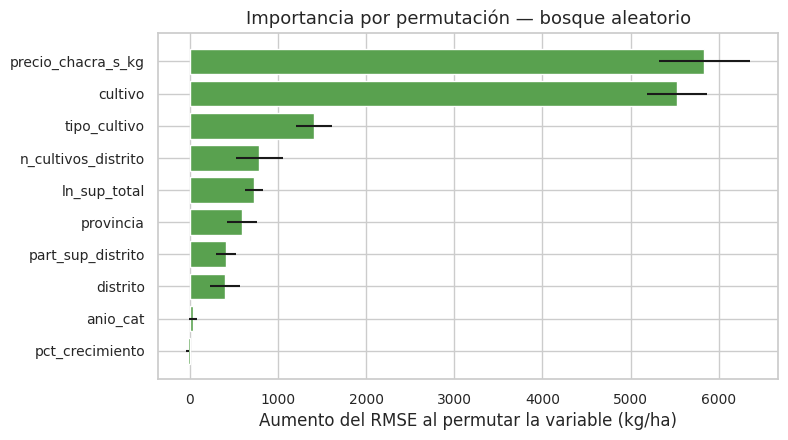

precio_chacra_s_kg     5836.0
cultivo                5528.0
tipo_cultivo           1411.0
n_cultivos_distrito     790.0
ln_sup_total            734.0
provincia               592.0
part_sup_distrito       412.0
distrito                400.0
anio_cat                 41.0
pct_crecimiento         -22.0
dtype: float64

In [37]:
# Importancia de cada variable original (permutación sobre el conjunto de prueba)
imp = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error")
imp_s = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(8, 4.5))
plt.barh(imp_s.index, imp_s.values, xerr=pd.Series(imp.importances_std, index=X_test.columns)[imp_s.index], color="#59a14f")
plt.xlabel("Aumento del RMSE al permutar la variable (kg/ha)"); plt.title("Importancia por permutación — bosque aleatorio"); plt.show()
imp_s.sort_values(ascending=False).round(0)

In [38]:
# ¿Cuánto depende el modelo del precio? (el precio se fija en el mercado y funciona como indicador del tipo de cultivo)
bp = gs.best_params_
sin_precio = [c for c in FEATURES_NUM if c != "precio_chacra_s_kg"]
rf_sp = build_pipeline(RandomForestRegressor(n_estimators=250, max_depth=bp["modelo__max_depth"],
                       min_samples_leaf=bp["modelo__min_samples_leaf"], max_features=bp["modelo__max_features"],
                       random_state=RANDOM_STATE, n_jobs=-1), num=sin_precio, escalar=False).fit(X_train, y_train)
comp_precio = pd.DataFrame({
    "Con precio": [mean_absolute_error(y_test, rf.predict(X_test)), rmse(y_test, rf.predict(X_test)), r2_score(y_test, rf.predict(X_test))],
    "Sin precio": [mean_absolute_error(y_test, rf_sp.predict(X_test)), rmse(y_test, rf_sp.predict(X_test)), r2_score(y_test, rf_sp.predict(X_test))]},
    index=["MAE", "RMSE", "R2"]).round(3)
comp_precio

,Con precio,Sin precio
MAE,2621.799,2428.858
RMSE,4313.180,3771.591
R2,0.864,0.896


### Actividad 17 — Importancia de variables
1. ¿Qué variables son más importantes? ¿Coincide con lo que vimos en el EDA y en el árbol?
2. ¿Qué mide la importancia por permutación y por qué es preferible a la importancia por impureza cuando hay variables categóricas con muchas categorías?
3. El precio en chacra aparece como la variable más importante. ¿Es una causa del rendimiento o un indicador del tipo de cultivo (la alfalfa y el maíz chala tienen rendimientos altos y precios bajos por kg)? Compara el modelo con y sin precio: ¿cuánto empeora?
4. ¿Qué **no** puedes concluir de la importancia (por ejemplo, causalidad o que cambiar el precio cambiaría el rendimiento)?

**Respuestas:** _(completar)_

### 7.6 Tabla comparativa de la unidad

In [39]:
# Extra: regresión lineal sobre el logaritmo del rendimiento (corrige la asimetría de la variable objetivo)
lin_log = evaluar("Lineal con objetivo log", TransformedTargetRegressor(
    regressor=build_pipeline(LinearRegression(), drop_first=True), func=np.log1p, inverse_func=np.expm1))

tabla = pd.DataFrame(resultados).set_index("Modelo")
ref = tabla.loc["Línea base: media global", "RMSE_test"]
tabla["Mejora RMSE vs media global (%)"] = (100 * (1 - tabla["RMSE_test"] / ref)).round(1)
cols_test = ["MAE_test", "RMSE_test", "R2_test", "Mejora RMSE vs media global (%)"]
tabla[["MAE_train", "RMSE_train", "R2_train"] + cols_test].round(3)

,MAE_train,RMSE_train,R2_train,MAE_test,RMSE_test,R2_test,Mejora RMSE vs media global (%)
Modelo,,,,,,,
Línea base: media global,9712.832,13099.762,0.000,8993.270,11681.775,-0.001,0.0
Línea base: media por cultivo,3324.793,6774.453,0.733,3155.635,5687.829,0.763,51.3
Regresión lineal múltiple,3533.467,5744.608,0.808,3558.397,5254.084,0.798,55.0
Regresión polinómica (grado 2),3247.570,5287.352,0.837,3443.081,5126.333,0.807,56.1
Árbol de regresión (prof. 11),1094.024,2048.167,0.976,3421.137,6184.665,0.720,47.1
Bosque aleatorio,971.630,1766.807,0.982,2621.799,4313.180,0.864,63.1
Lineal con objetivo log,2952.007,5624.850,0.816,2984.681,4877.362,0.826,58.2


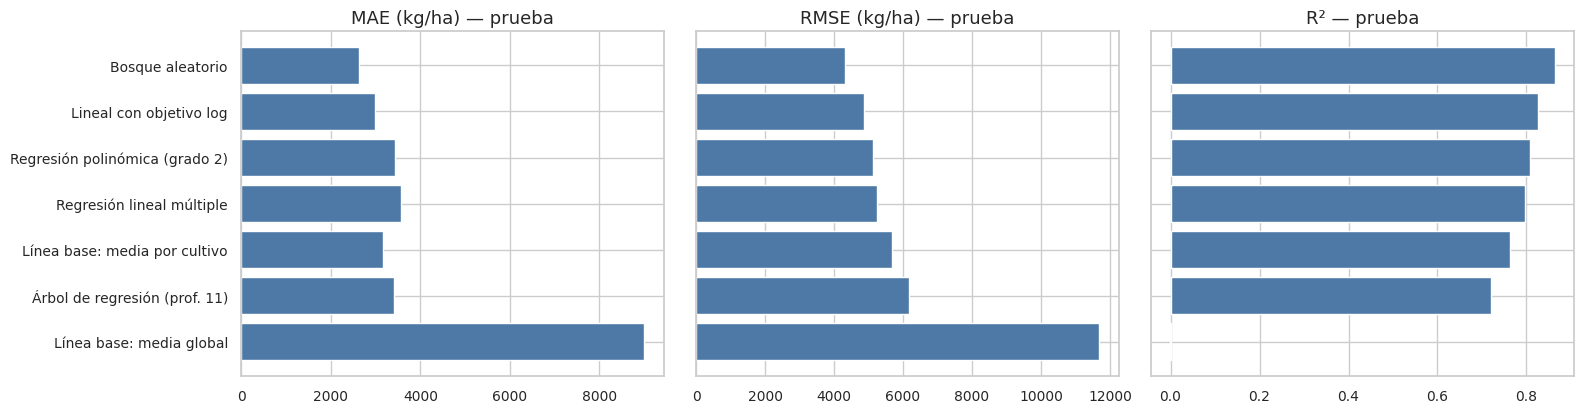

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
orden = tabla.sort_values("RMSE_test", ascending=False).index
for ax, m, ttl in zip(axes, ["MAE_test", "RMSE_test", "R2_test"], ["MAE (kg/ha)", "RMSE (kg/ha)", "R²"]):
    ax.barh(orden, tabla.loc[orden, m], color="#4e79a7"); ax.set_title(ttl + " — prueba")
plt.tight_layout(); plt.show()

Mejor modelo por RMSE en prueba: Bosque aleatorio


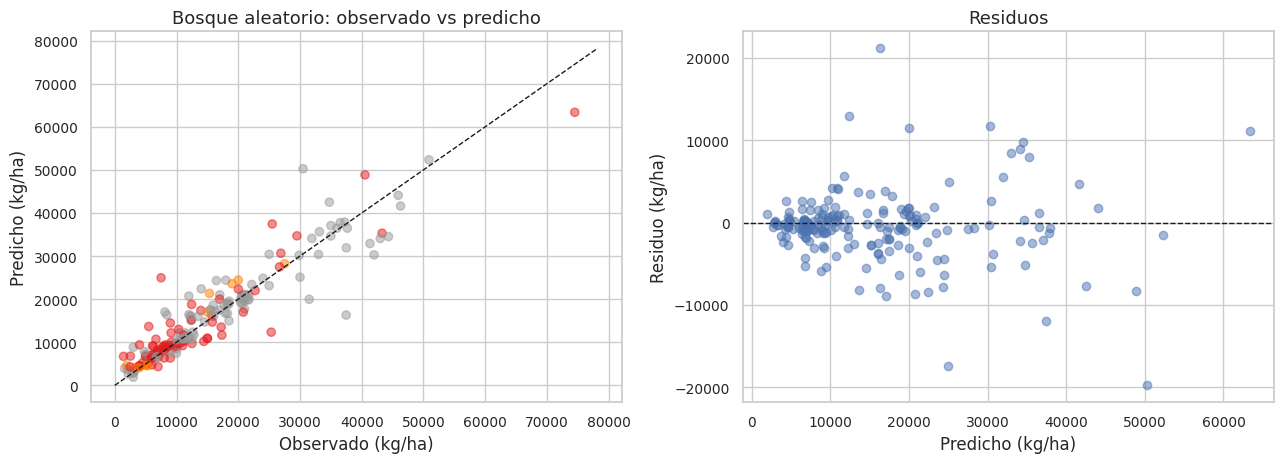

In [41]:
mejor = tabla.drop(index=["Línea base: media global", "Línea base: media por cultivo"])["RMSE_test"].idxmin()
print("Mejor modelo por RMSE en prueba:", mejor)
modelo_mejor = {"Regresión lineal múltiple": lin, "Bosque aleatorio": rf, "Lineal con objetivo log": lin_log}.get(mejor, rf)
pred = modelo_mejor.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
lim = [0, max(y_test.max(), pred.max()) * 1.05]
axes[0].scatter(y_test, pred, alpha=.5, c=base.loc[y_test.index, "tipo_cultivo"].astype("category").cat.codes, cmap="Set1")
axes[0].plot(lim, lim, "k--", lw=1); axes[0].set_xlabel("Observado (kg/ha)"); axes[0].set_ylabel("Predicho (kg/ha)")
axes[0].set_title(f"{mejor}: observado vs predicho")
resid = y_test - pred
axes[1].scatter(pred, resid, alpha=.5); axes[1].axhline(0, color="k", ls="--", lw=1)
axes[1].set_xlabel("Predicho (kg/ha)"); axes[1].set_ylabel("Residuo (kg/ha)"); axes[1].set_title("Residuos")
plt.tight_layout(); plt.show()

### Actividad 18 — Conclusión de la comparación
1. ¿Qué modelo es mejor y cuánto mejora a las dos líneas base? ¿Supera a la **media por cultivo**? ¿Qué significa que lo supere por poco o por mucho?
2. Compara el error de entrenamiento con el de prueba de cada modelo: ¿cuáles sobreajustan?
3. Interpreta el MAE y el RMSE en kg/ha para un cultivo concreto (por ejemplo, papa con ~20 000 kg/ha de rendimiento típico). ¿Es un error aceptable?
4. En el gráfico de residuos, ¿hay patrones (heterocedasticidad)? ¿Dónde se equivoca más el modelo?

**Respuestas:** _(completar)_

### 7.7 Curva de aprendizaje
¿Ayudaría tener más datos? Se compara el error de entrenamiento y de validación al crecer el tamaño de la muestra.

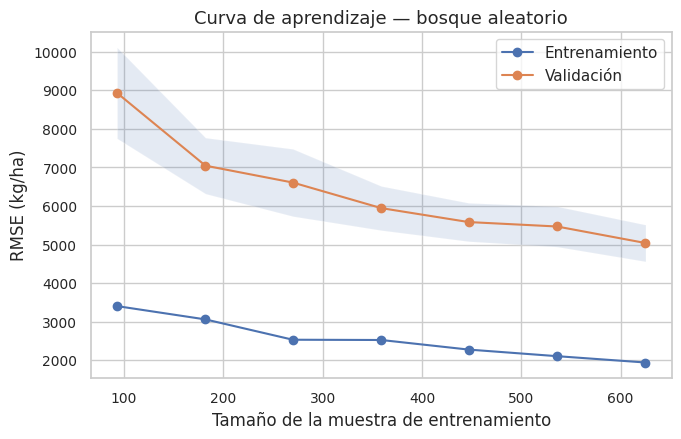

In [42]:
sizes, tr, va = learning_curve(clone(gs.best_estimator_), X_train, y_train, cv=KF, scoring="neg_root_mean_squared_error",
                               train_sizes=np.linspace(0.15, 1.0, 7), n_jobs=-1, random_state=RANDOM_STATE)
plt.figure(figsize=(7.5, 4.5))
plt.plot(sizes, -tr.mean(1), "o-", label="Entrenamiento"); plt.plot(sizes, -va.mean(1), "o-", label="Validación")
plt.fill_between(sizes, -va.mean(1) - va.std(1), -va.mean(1) + va.std(1), alpha=.15)
plt.xlabel("Tamaño de la muestra de entrenamiento"); plt.ylabel("RMSE (kg/ha)"); plt.title("Curva de aprendizaje — bosque aleatorio")
plt.legend(); plt.show()

### 7.8 Validación más exigente (extra)

Una sola división aleatoria puede ser optimista: el mismo cultivo en el mismo distrito aparece en **tres años** con valores parecidos, de modo que una fila de prueba puede tener una "hermana" casi idéntica en el entrenamiento. Se evalúan dos escenarios más difíciles:  
**(a)** validación por grupos: ninguna combinación distrito–cultivo se ve a la vez en entrenamiento y prueba;  
**(b)** entrenar con 2021–2022 y evaluar en 2023.

In [43]:
scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}
cands = {"Línea base: media por cultivo": MediaPorCultivo(),
         "Regresión lineal múltiple": build_pipeline(LinearRegression(), drop_first=True),
         "Bosque aleatorio": clone(gs.best_estimator_)}
filas = []
gkf = GroupKFold(n_splits=5)
for nombre, m in cands.items():
    cvr = cross_validate(m, X, y, groups=grupos, cv=gkf, scoring=scoring)
    filas.append(dict(Modelo=nombre, Escenario="(a) por grupos distrito–cultivo", MAE=-cvr["test_MAE"].mean(),
                      RMSE=-cvr["test_RMSE"].mean(), R2=cvr["test_R2"].mean()))
tr_idx = (base["anio"] <= 2022).values; te_idx = ~tr_idx
for nombre, m in cands.items():
    mm = clone(m).fit(X[tr_idx], y[tr_idx]); pp = mm.predict(X[te_idx])
    filas.append(dict(Modelo=nombre, Escenario="(b) entrenar 2021–22 → probar 2023", MAE=mean_absolute_error(y[te_idx], pp),
                      RMSE=rmse(y[te_idx], pp), R2=r2_score(y[te_idx], pp)))
robusta = pd.DataFrame(filas).round(3)
robusta

,Modelo,Escenario,MAE,RMSE,R2
0,Línea base: media por cultivo,(a) por grupos distrito–cultivo,3953.038,7235.989,0.668
1,Regresión lineal múltiple,(a) por grupos distrito–cultivo,4579.024,7076.280,0.662
2,Bosque aleatorio,(a) por grupos distrito–cultivo,3643.672,6229.494,0.754
3,Línea base: media por cultivo,(b) entrenar 2021–22 → probar 2023,3508.632,6724.649,0.722
4,Regresión lineal múltiple,(b) entrenar 2021–22 → probar 2023,3501.801,5658.231,0.803
5,Bosque aleatorio,(b) entrenar 2021–22 → probar 2023,3146.908,5118.755,0.839


### 7.9 Sensibilidad a los valores atípicos (extra)
¿Cambia el resultado si se entrena el bosque aleatorio **sin** los atípicos por cultivo?

In [44]:
atip_train = base.loc[X_train.index, "atipico_cultivo"].values
rf_sin = clone(gs.best_estimator_).fit(X_train[~atip_train], y_train[~atip_train])
sin = pd.DataFrame({
    "Entrenado con todos": [mean_absolute_error(y_test, rf.predict(X_test)), rmse(y_test, rf.predict(X_test)), r2_score(y_test, rf.predict(X_test))],
    "Entrenado sin atípicos": [mean_absolute_error(y_test, rf_sin.predict(X_test)), rmse(y_test, rf_sin.predict(X_test)), r2_score(y_test, rf_sin.predict(X_test))]},
    index=["MAE", "RMSE", "R2"]).round(3)
print(f"Atípicos retirados del entrenamiento: {int(atip_train.sum())} de {len(atip_train)}"); sin

Atípicos retirados del entrenamiento: 45 de 782


,Entrenado con todos,Entrenado sin atípicos
MAE,2621.799,2644.494
RMSE,4313.180,4491.288
R2,0.864,0.852


### Actividad 19 — Robustez
1. ¿Cuánto empeoran los modelos en los escenarios (a) y (b) frente a la división aleatoria? ¿Qué te dice sobre cuánto del buen resultado era "memorizar" combinaciones conocidas?
2. ¿Se mantiene el orden entre modelos? ¿Sigue superando el bosque a la línea base por cultivo?
3. ¿Retirar los atípicos mejora el desempeño? ¿Confirma tu decisión de conservarlos?

**Respuestas:** _(completar)_

## 8. De los datos al conocimiento y a una propuesta
Los datos producen conocimiento y su fin es orientar decisiones. Aquí se identifican **brechas de rendimiento**: distritos que, para el mismo cultivo, rinden por debajo de lo esperado.

Una cautela previa: el mismo cultivo rinde muy distinto según la zona. La alfalfa, por ejemplo, va de ~12 000 kg/ha en distritos altoandinos a más de 80 000 kg/ha en el valle de Tacna. Comparar un distrito contra la mediana de **toda la región** mezclaría diferencias agroclimáticas (altitud, temperatura, número de cortes al año) con diferencias de manejo. Por eso se usan tres miradas y se comprueba si coinciden:

- **(A) Relativa a la región:** rendimiento ÷ mediana del cultivo en toda la región. *Útil como panorama, pero injusta con las zonas altoandinas.*
- **(B) Relativa a la provincia:** rendimiento ÷ mediana del mismo cultivo **dentro de su provincia** (compara zonas más parecidas). *Es la más adecuada para priorizar, aunque imperfecta: la provincia de Tacna mezcla distritos de costa y de sierra (p. ej., Sama o La Yarada frente a Palca o Pachía).*
- **(C) Con modelo:** un modelo *sin variables de ubicación* predice el rendimiento a partir del cultivo, la superficie, el precio, etc. El **residuo** (observado − esperado) captura lo que la ubicación aporta. Se usan predicciones fuera de muestra (validación por grupos) para no premiar la memorización.

In [45]:
# (A) relativa a la región  |  (B) relativa a la provincia
eda2 = base[base["cultivo"].isin(cult_ok)].copy()
eda2["med_region"] = eda2.groupby("cultivo")["rendimiento_kg_ha"].transform("median")
g_prov = eda2.groupby(["cultivo", "provincia"])["rendimiento_kg_ha"]
eda2["med_prov"] = np.where(g_prov.transform("size") >= 6, g_prov.transform("median"), np.nan)   # mínimo 6 registros por cultivo-provincia
eda2["rel_region"] = eda2["rendimiento_kg_ha"] / eda2["med_region"]
eda2["rel_prov"] = eda2["rendimiento_kg_ha"] / eda2["med_prov"]
eda2["brecha_region_t"] = np.clip(eda2["med_region"] - eda2["rendimiento_kg_ha"], 0, None) * eda2["sup_cosechada_ha"] / 1000
eda2["brecha_prov_t"] = np.clip(eda2["med_prov"] - eda2["rendimiento_kg_ha"], 0, None) * eda2["sup_cosechada_ha"] / 1000
A = eda2.groupby("distrito").agg(provincia=("provincia", "first"), n=("rel_region", "size"),
        rel_region=("rel_region", "median"), rel_prov=("rel_prov", "median"),
        brecha_region_t=("brecha_region_t", "sum"), brecha_prov_t=("brecha_prov_t", "sum")).reset_index()

# (C) modelo sin ubicación, predicción fuera de muestra por grupos
cat_sin_ubic = ["cultivo", "tipo_cultivo", "anio_cat"]
modelo_b = build_pipeline(RandomForestRegressor(n_estimators=250, min_samples_leaf=3, max_features=0.7, random_state=RANDOM_STATE, n_jobs=-1),
                          cat=cat_sin_ubic, escalar=False)
pred_b = cross_val_predict(modelo_b, X, y, groups=grupos, cv=GroupKFold(n_splits=5))
b = base.assign(pred_b=pred_b, resid_rel=(y - pred_b) / pred_b)
b = b[b["cultivo"].isin(cult_ok)]
B = b.groupby("distrito").agg(resid_rel=("resid_rel", "median")).reset_index()

pol = A.merge(B, on="distrito").sort_values("rel_prov")
for a_, b_ in [("rel_region", "resid_rel"), ("rel_prov", "resid_rel"), ("rel_region", "rel_prov")]:
    rho, pval = st.spearmanr(pol[a_], pol[b_], nan_policy="omit")
    print(f"Spearman entre distritos: {a_} vs {b_}: rho = {rho:.2f} (p = {pval:.3f})")
pol[["distrito", "provincia", "n", "rel_region", "rel_prov", "resid_rel", "brecha_region_t", "brecha_prov_t"]].round(2)

Spearman entre distritos: rel_region vs resid_rel: rho = 0.65 (p = 0.000)
Spearman entre distritos: rel_prov vs resid_rel: rho = 0.69 (p = 0.000)
Spearman entre distritos: rel_region vs rel_prov: rho = 0.88 (p = 0.000)


,distrito,provincia,n,rel_region,rel_prov,resid_rel,brecha_region_t,brecha_prov_t
16,PALCA,TACNA,17,0.89,0.66,-0.16,315.14,4403.72
6,ESTIQUE,TARATA,24,0.79,0.74,-0.13,2864.74,1895.61
24,TARUCACHI,TARATA,17,0.88,0.86,-0.15,1137.34,742.28
7,ESTIQUE PAMPA,TARATA,22,0.90,0.91,-0.07,1144.40,568.23
2,CAMILACA,CANDARAVE,17,0.95,0.92,-0.10,11544.64,1880.76
15,PACHIA,TACNA,66,0.95,0.94,-0.08,2040.46,10549.42
0,CAIRANI,CANDARAVE,16,0.98,0.98,-0.05,39530.32,1193.54
19,SAMA,TACNA,35,0.94,0.98,-0.07,8602.28,1866.58
17,POCOLLAY,TACNA,63,1.00,1.00,-0.01,328.57,311.19
11,INCLAN,TACNA,30,0.94,1.00,-0.09,6771.13,843.90


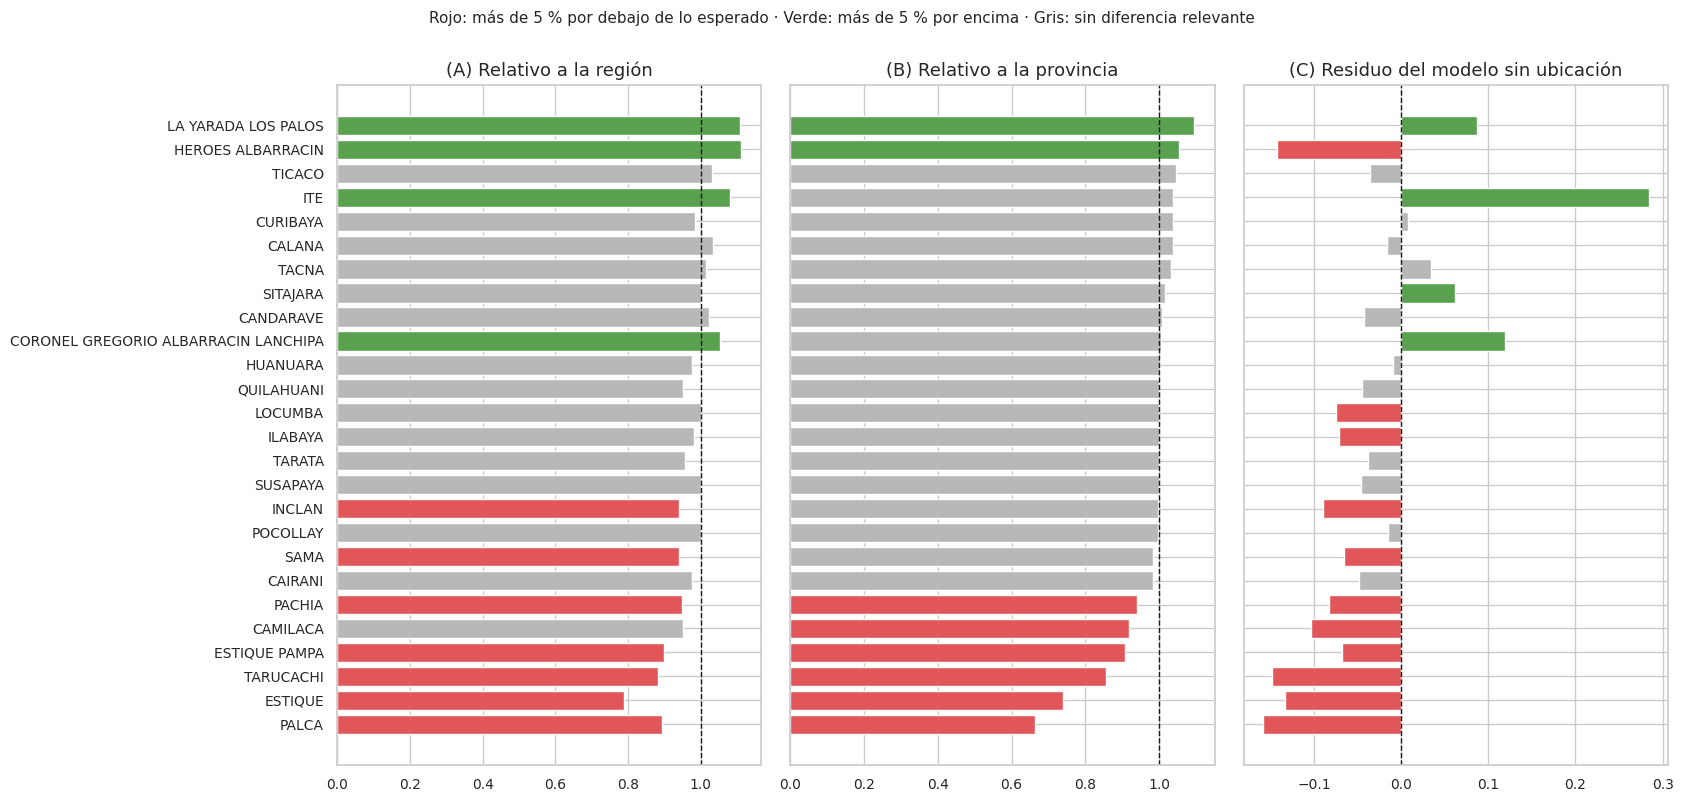

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)
orden = pol["distrito"]
TOL = 0.05   # banda de tolerancia: ±5 % se considera "sin diferencia relevante"
for ax, col, ref, ttl in zip(axes, ["rel_region", "rel_prov", "resid_rel"], [1, 1, 0],
        ["(A) Relativo a la región", "(B) Relativo a la provincia", "(C) Residuo del modelo sin ubicación"]):
    v = pol[col]
    colores = np.where(v < ref - TOL, "#e15759", np.where(v > ref + TOL, "#59a14f", "#b8b8b8"))
    ax.barh(orden, v, color=colores); ax.axvline(ref, color="k", ls="--", lw=1); ax.set_title(ttl)
fig.suptitle("Rojo: más de 5 % por debajo de lo esperado · Verde: más de 5 % por encima · Gris: sin diferencia relevante", y=1.0, fontsize=11)
plt.tight_layout(); plt.show()

In [47]:
# ¿Dónde está la mayor brecha en toneladas? Comparación con la mediana de la PROVINCIA (más justa) y de la región
print("Distritos con mayor brecha (t, suma 2021–2023) respecto a la mediana de su provincia:")
print(A.sort_values("brecha_prov_t", ascending=False)[["distrito", "provincia", "rel_prov", "brecha_prov_t", "brecha_region_t"]].head(8).round(1).to_string(index=False))
G = eda2.groupby(["provincia", "distrito", "cultivo"]).agg(n=("rel_prov", "size"), rel_prov=("rel_prov", "median"),
        brecha_prov_t=("brecha_prov_t", "sum"), brecha_region_t=("brecha_region_t", "sum")).reset_index()
print("\nCombinaciones distrito–cultivo con mayor brecha respecto a su provincia:")
print(G.sort_values("brecha_prov_t", ascending=False).head(10).round(2).to_string(index=False))
print("\nPara contrastar, mayor brecha respecto a la región (mezcla zonas agroclimáticas):")
print(G.sort_values("brecha_region_t", ascending=False).head(5)[["distrito", "cultivo", "rel_prov", "brecha_region_t"]].round(2).to_string(index=False))

Distritos con mayor brecha (t, suma 2021–2023) respecto a la mediana de su provincia:
           distrito     provincia  rel_prov  brecha_prov_t  brecha_region_t
             PACHIA         TACNA       0.9        10549.4           2040.5
LA YARADA LOS PALOS         TACNA       1.1         7631.2           6264.9
            LOCUMBA JORGE BASADRE       1.0         7384.6           1204.3
             TARATA        TARATA       1.0         4951.5          18389.5
              PALCA         TACNA       0.7         4403.7            315.1
            ESTIQUE        TARATA       0.7         1895.6           2864.7
           CAMILACA     CANDARAVE       0.9         1880.8          11544.6
               SAMA         TACNA       1.0         1866.6           8602.3

Combinaciones distrito–cultivo con mayor brecha respecto a su provincia:
    provincia            distrito    cultivo  n  rel_prov  brecha_prov_t  brecha_region_t
        TACNA              PACHIA    ALFALFA  3      0.46        9

### Actividad 20 — Lectura crítica de las brechas
1. ¿Coinciden las tres miradas? Interpreta las correlaciones de Spearman entre ellas.
2. ¿Qué cambia entre la mirada (A) y la (B)? ¿Por qué la brecha de la alfalfa de Candarave se reduce o desaparece al comparar con su propia provincia?
3. ¿Qué distritos aparecen consistentemente por debajo del rendimiento esperado en (B) y (C)?
4. ¿Qué **no** se puede concluir? Piensa en altitud, clima, suelo, acceso a agua, tecnificación y tamaño de parcela, que no están en los datos, y en que la mediana es un punto de comparación, no una meta.
5. Con la brecha en toneladas (B), ¿dónde tendría más impacto actuar primero y qué información adicional pedirías antes de decidir?

**Respuestas:** _(completar)_

### Hallazgos y propuesta de política
> _Esta sección es el producto final del análisis: redáctala con tus palabras y tus cifras, tras responder las actividades. Estructura sugerida:_

**Hallazgos (qué dicen los datos)**
1. _(p. ej.: qué explica más del rendimiento: el cultivo, y cuánto mejora el mejor modelo respecto a la línea base)_
2. _(p. ej.: variables adicionales que importan; cómo cambió el rendimiento entre 2021 y 2023)_
3. _(p. ej.: distritos con rendimiento sistemáticamente menor al esperado para el mismo cultivo)_

**Propuesta (qué se haría con ello)**
- _Acción concreta, dónde, a quién beneficia y con qué evidencia (p. ej.: asistencia técnica focalizada en los distritos y cultivos con mayor brecha; diseñar el programa piloto y cómo medir si la brecha se cierra)._
- _Qué información faltaría recoger antes de decidir (altitud, riego, tamaño de parcela, costos)._

**Cautelas:** correlación no implica causalidad; solo 3 campañas; datos preliminares; precios y rendimientos agregados por distrito, no por productor.

## 9. Limitaciones y conclusiones
**Limitaciones**
- Solo tres campañas (2021–2023) y cifras marcadas como *información preliminar* en el anuario.
- Los datos están agregados por distrito: no se observa el productor, el tamaño de la parcela ni el riego.
- Se excluyeron 62 filas de distritos con nombre inferido y 27 cultivos en crecimiento sin cosecha.
- El mismo cultivo y distrito se repite entre años: la división aleatoria es optimista (ver 7.8).
- El anuario no trae coordenadas; no se pudo construir un mapa.

**Conclusiones** _(completar tras analizar los resultados)_

**Trabajo futuro:** ampliar a 2024–2025 (anuarios en PDF), agregar coordenadas y altitud por distrito, incorporar variables climáticas y comparar con otros departamentos del SIEA.

---
### Declaración de uso de herramientas de IA generativa
> Conforme al sílabo (6.3, numeral 7), se declara el uso de herramientas de IA: **herramienta:** _(Claude, de Anthropic, u otra)_; **propósito:** _(p. ej.: apoyo para localizar fuentes de datos, limpiar y unir los archivos del anuario, estructurar el notebook y revisar el código)_. Las interpretaciones, decisiones y conclusiones son del equipo.

### Referencias
- Gobierno Regional de Tacna – Dirección Regional de Agricultura. *Anuario Estadístico Agrícola 2021, 2022, 2023*. Plataforma Nacional de Datos Abiertos (datosabiertos.gob.pe).
- Pedregosa et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR 12, 2825–2830.
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow* (3.ª ed.). O'Reilly.
- James, Witten, Hastie, Tibshirani (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer.